In [2]:
import os 
import pandas as pd
from tqdm import tqdm
from collections import Counter, defaultdict
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef

path_benchmark = "/media/concha-eloko/Linux/PPT_clean/benchmark"
path_panels = "/media/concha-eloko/Linux/papers/PPT/reviewed_new_figures/panels"

In [ ]:
import json
from itertools import product
import random

PATH_WORK = "/media/concha-eloko/Linux/PPT_clean"
df_info = pd.read_csv(f"{PATH_WORK}/TropiGATv2.final_df_v2.tsv", sep="\t", header=0)
df_info_final = df_info[~df_info["KL_type_LCA"].str.contains("\\|")]
kltypes = df_info_final["KL_type_LCA"].unique().tolist()

***
### Overview and functions:

In [59]:
import os 
import pandas as pd
import numpy as np
from tqdm import tqdm
from collections import Counter
from statistics import mean, median

path_benchmark = "/media/concha-eloko/Linux/PPT_clean/benchmark"
path_benchmark_r = "/media/concha-eloko/Linux/PPT_clean/benchmark/review"

os.makedirs(path_benchmark_r, exist_ok=True)

results_bench_df = pd.read_csv(f"{path_benchmark}/Prediction_results.v5.matrices.tsv", sep = "\t", index_col = False, header = 0)
results_bench_df["SpikeHunter_prediction"] = [kltype.replace("K", "KL") for kltype in results_bench_df["SpikeHunter_prediction"] if kltype.count("KL")==0]

In [14]:
# Fold data
path_project = "/media/concha-eloko/Linux/PPT_clean"
df_folds = pd.read_csv(f"{path_project}/in_vitro/dpos_folds.all_matrices.tsv", header = 0, sep = "\t")

# Target data
path_finetuning = "/media/concha-eloko/Linux/PPT_clean/in_vitro/fine_tuning"
bea_df = pd.read_csv(f"{path_finetuning}/bea_fine_tuning.df", sep = "\t", header = 0)
bea_df["Protein"] = bea_df["Protein"].apply(lambda x : x.replace("_", "__"))
pool_bea = set([kltype.strip() for kltypes in bea_df["Target"] for kltype in kltypes.split(",") if kltype.count("wzi") == 0 if kltype.count("pass") == 0])

ferriol_df = pd.read_csv(f"{path_finetuning}/ferriol_fine_tuning.df", sep = "\t", header = 0)
#ferriol_df["Target"] = ferriol_df["Target"].apply(lambda x : x.replace("K", "KL"))
pool_ferriol = set([kltype.strip() for kltypes in ferriol_df["Target"] for kltype in kltypes.split(",") if kltype.count("wzi") == 0 if kltype.count("pass") == 0])

towndsend_df = pd.read_csv(f"{path_finetuning}/towndsend_fine_tuning.df", sep = "\t", header = 0)
towndsend_df["Protein"] = towndsend_df["Protein"].apply(lambda x : x.replace("_", "__"))
pool_towndsend = set([kltype.strip() for kltypes in towndsend_df["Target"] for kltype in kltypes.split(",") if kltype.count("wzi") == 0 if kltype.count("pass") == 0])

dico_matrices = {"ferriol" : {"matrix" : ferriol_df, "pool" : pool_ferriol}, 
                 "bea" : {"matrix": bea_df, "pool" : pool_bea}, 
                 "towndsend" : {"matrix" : towndsend_df, "pool" : pool_towndsend}}

# targets dico : 
dico_hits = {}
for author in dico_matrices :
    matrix = dico_matrices[author]["matrix"]
    for _, row in matrix.iterrows() : 
        for phage in matrix["Phages"].unique() : 
            all_targets = set()
            targets = matrix[matrix["Phages"] == phage]["Target"].values
            for calls in targets : 
                actual_targets = [x.strip() for x in calls.split(",")]
                all_targets.update(actual_targets)
            dico_hits[phage] = all_targets


> Functions: 

In [76]:
# Useful functions: 
def make_labels(pred_df, predictor = "tropigat" , top_n = 40, to_ignore = []) :
    dico_pred = {"tropigat" : "TropiGAT_prediction" ,
                 "tropigat_uf" : "TropiGAT_new_UF_prediction", 
                 "tropiseq" : "TropiSEQ_prediction", 
                 "tropiseq_uf" : "TropiSEQ_UF_prediction", 
                 "spikehunter" : "SpikeHunter_prediction", 
                 "tropilr" : "TropiLogReg_prediction", 
                 "tropisage" : "TropiSAGE_prediction"}
    col = dico_pred[predictor]
    labels_tropigat = {}
    all_kl_types = set(kltype.strip() for row in results_bench_df["Targets"] for kltype in row.split(","))
    count_kltypes = {}
    dico_prophage_count = all_kl_types
    for kltype in tqdm(dico_prophage_count) : 
        n = 0
        pred_labels , real_labels = [] , []
        for author in dico_matrices :
            if kltype in dico_matrices[author]["pool"] : 
                matrix = dico_matrices[author]["matrix"]
                for phage in matrix["Phages"].unique() :
                    #if phage not in to_ignore : 
                    if phage not in to_ignore and phage in pred_df["phage"].tolist(): 
                        top_predictions = set()
                        predictions = pred_df[pred_df["phage"] == phage][col].values
                        for calls in predictions : 
                            if calls == "No hits" or calls == "No_hits":
                                predicted_kltypes = []
                            elif predictor == "spikehunter" :
                                predicted_kltypes = [x.split(":")[0].strip().replace("K", "KL") for x in calls.split(";")]
                            else :
                                #predicted_kltypes = [x.split(":")[0].strip() for x in calls.split(";") if float(x.split(":")[1]) >= 0.5]
                                predicted_kltypes = [x.split(":")[0].strip() for x in calls.split(";") if float(x.split(":")[1]) >= 0.0]
                            top_predictions.update(predicted_kltypes[0:top_n-1])
                        if kltype in top_predictions : 
                            pred_labels.append(1)
                        else : 
                            pred_labels.append(0)
                        if kltype in dico_hits[phage] : 
                            real_labels.append(1)
                            n += 1 
                        else :
                            real_labels.append(0)
        labels_tropigat[kltype] = {"y_pred" : pred_labels, "real_labels" : real_labels}
        sorted_dict = dict(sorted(labels_tropigat.items(), key=lambda item: int(item[0].split("KL")[1])))
        count_kltypes[kltype] = n 
    return sorted_dict , labels_tropigat, count_kltypes

def random_selection_and_ranking(elements, dico_matrix, top_n, bootstrap, threshold = 0.01):
    list_bootstrap = []
    combinations_00 = [list(product([phage], targets_list)) for phage, targets_list in dico_matrix.items()]
    combinations = [item for items in combinations_00 for item in items]
    for _ in range(bootstrap):
        track_recall = [0] * (top_n+1)
        count_top_n = 0
        for phage in dico_matrix :
            rank = sorted(
                [(element,rand_num) for element, rand_num in {element:random.random() for element in elements}.items() if rand_num > threshold],
                key=lambda x: x[1],
                reverse=True)
            #print(rank)
            for i in range(1,top_n+1) :
                top_i = set([(phage,item[0]) for item in rank[0:i]])
                random_found = len(top_i & set(combinations))
                track_recall[i] = track_recall[i] + random_found
        list_bootstrap.append(track_recall)
    return list_bootstrap

def random_selection_and_ranking(elements, dico_matrix, top_n, bootstrap, threshold=0.01):
    """
    Optimized version using NumPy for faster computation and memory efficiency.
    Returns mean values across all bootstrap iterations for each position.
    
    Args:
        elements: List of elements to select from
        dico_matrix: Dictionary containing phage-target mappings
        top_n: Number of top elements to consider
        bootstrap: Number of bootstrap iterations
        threshold: Minimum threshold for random numbers (default: 0.01)
    
    Returns:
        numpy.ndarray: Array of mean values for each position across all bootstraps
    """
    # Pre-compute combinations once
    combinations_00 = [list(product([phage], targets_list)) 
                      for phage, targets_list in dico_matrix.items()]
    combinations = set(item for items in combinations_00 for item in items)
    
    # Initialize result array
    results = np.zeros((bootstrap, top_n + 1))
    n_elements = len(elements)
    
    # Pre-compute elements array for faster lookup
    elements_array = np.array(list(elements))
    
    for b in range(bootstrap):
        # Generate all random numbers at once
        rand_nums = np.random.random(n_elements)
        mask = rand_nums > threshold
        
        # Get valid indices and their corresponding random numbers
        valid_indices = np.where(mask)[0]
        valid_rand_nums = rand_nums[valid_indices]
        
        # Sort indices by random numbers
        sorted_indices = valid_indices[np.argsort(-valid_rand_nums)]
        sorted_elements = elements_array[sorted_indices]
        
        for phage in dico_matrix:
            for i in range(1, top_n + 1):
                top_i = set((phage, elem) for elem in sorted_elements[:i])
                results[b, i] += len(top_i & combinations)
    
    # Calculate mean across all bootstrap iterations
    return np.round(np.mean(results, axis=0)).astype(int)

    
def make_labels(pred_df, predictor = "tropigat" , top_n = 40, to_ignore = []) :
    dico_pred = {"tropigat" : "TropiGAT_prediction" ,
                 "tropigat_uf" : "TropiGAT_new_UF_prediction", 
                 "tropiseq" : "TropiSEQ_prediction", 
                 "tropiseq_uf" : "TropiSEQ_UF_prediction", 
                 "spikehunter" : "SpikeHunter_prediction", 
                 "tropigat_new" : "TropiGAT_new_prediction", 
                 "tropilr" : "TropiLogReg_prediction", 
                 "tropisage" : "TropiSAGE_prediction"}
    col = dico_pred[predictor]
    labels_tropigat = {}
    all_kl_types = set(kltype.strip() for row in results_bench_df["Targets"] for kltype in row.split(","))
    count_kltypes = {}
    dico_prophage_count = all_kl_types
    for kltype in tqdm(dico_prophage_count) : 
        n = 0
        pred_labels , real_labels = [] , []
        for author in dico_matrices :
            if kltype in dico_matrices[author]["pool"] : 
                matrix = dico_matrices[author]["matrix"]
                for phage in matrix["Phages"].unique() :
                    #if phage not in to_ignore : 
                    if phage not in to_ignore and phage in pred_df["phage"].tolist(): 
                        top_predictions = set()
                        predictions = pred_df[pred_df["phage"] == phage][col].values
                        for calls in predictions : 
                            if predictor == "spikehunter" :
                                predicted_kltypes = [x.split(":")[0].strip().replace("K", "KL") for x in calls.split(";")]
                            else :
                                predicted_kltypes = [x.split(":")[0].strip() for x in calls.split(";")]
                            top_predictions.update(predicted_kltypes[0:top_n-1])
                        if kltype in top_predictions : 
                            pred_labels.append(1)
                        else : 
                            pred_labels.append(0)
                        if kltype in dico_hits[phage] : 
                            real_labels.append(1)
                            n += 1 
                        else :
                            real_labels.append(0)
        labels_tropigat[kltype] = {"y_pred" : pred_labels, "real_labels" : real_labels}
        sorted_dict = dict(sorted(labels_tropigat.items(), key=lambda item: int(item[0].split("KL")[1])))
        count_kltypes[kltype] = n 
    return sorted_dict , labels_tropigat, count_kltypes


def decript_dic(sorted_dict, labels_tropigat, count_kltypes, print_df=True):
    # Initialize lists to collect metrics when print_df is False
    kltypes, counts, f1_scores, accuracies, recalls, precisions, aucs, mccs = ([] for _ in range(8))
    
    if print_df:
        print("KL type", "Count", "F1", "Accuracy", "Recall", "Precision", "AUC", "MCC", sep="\t")
    
    for kltype in sorted_dict:
        if len(labels_tropigat[kltype]["real_labels"]) > 1:
            if Counter(labels_tropigat[kltype]["y_pred"])[1] == 0:
                if print_df:
                    print(kltype, count_kltypes[kltype], "error", sep="\t")
                else:
                    # Append NaN for each metric when Counter condition is met
                    kltypes.append(kltype)
                    counts.append(count_kltypes[kltype])
                    f1_scores.append(np.nan)
                    accuracies.append(np.nan)
                    recalls.append(np.nan)
                    precisions.append(np.nan)
                    aucs.append(np.nan)
                    mccs.append(np.nan)
            else:
                try:
                    # Calculate each metric
                    f1 = f1_score(labels_tropigat[kltype]["real_labels"], labels_tropigat[kltype]["y_pred"], average='binary')
                    precision = precision_score(labels_tropigat[kltype]["real_labels"], labels_tropigat[kltype]["y_pred"], average='binary')
                    recall = recall_score(labels_tropigat[kltype]["real_labels"], labels_tropigat[kltype]["y_pred"], average='binary')
                    mcc = matthews_corrcoef(labels_tropigat[kltype]["real_labels"], labels_tropigat[kltype]["y_pred"])
                    accuracy = accuracy_score(labels_tropigat[kltype]["real_labels"], labels_tropigat[kltype]["y_pred"])
                    auc = roc_auc_score(labels_tropigat[kltype]["real_labels"], labels_tropigat[kltype]["y_pred"])
                    
                    if print_df:
                        print(kltype, count_kltypes[kltype], round(f1, 5), round(accuracy, 5), round(recall, 5), 
                              round(precision, 5), round(auc, 5), round(mcc, 5), sep="\t")
                    else:
                        # Append each metric to the corresponding list
                        kltypes.append(kltype)
                        counts.append(count_kltypes[kltype])
                        f1_scores.append(f1)
                        accuracies.append(accuracy)
                        recalls.append(recall)
                        precisions.append(precision)
                        aucs.append(auc)
                        mccs.append(mcc)                        
                except ValueError:
                    if print_df:
                        print(kltype, "error", sep="\t")
                    else:
                        # Append NaN values when a ValueError occurs
                        kltypes.append(kltype)
                        counts.append(count_kltypes[kltype])
                        f1_scores.append(np.nan)
                        accuracies.append(np.nan)
                        recalls.append(np.nan)
                        precisions.append(np.nan)
                        aucs.append(np.nan)
                        mccs.append(np.nan)

    # Return lists when print_df is False
    if not print_df:
        dataframe = pd.DataFrame({
            "KL type": kltypes,
            "Count": counts,
            "F1": f1_scores,
            "Accuracy": accuracies,
            "Recall": recalls,
            "Precision": precisions,
            "AUC": aucs,
            "MCC": mccs
        })
        dataframe = dataframe[dataframe["Count"] > 0]
        return dataframe

    
def get_good_calls(df) :
    from collections import defaultdict
    
    n_cols_interest = 0
    # Make list of the predictions col names :
    cols_predictors = []
    for col in df.columns: 
        if col.count("good_calls") > 0 :
            cols_predictors.append(col)
    good_calls_dico = defaultdict(list)
    # iterate through the predictions : 
    for predictor in cols_predictors :
        good_calls_list = df[predictor].tolist()
        for phage, good_calls in zip(df["phage"].tolist(), good_calls_list) :
            if good_calls != "0" :
                for call in good_calls.split(",") :
                    a = (phage, call)
                    good_calls_dico[predictor].append(a)
    return good_calls_dico
                
    
def get_good_calls_extended(df, threshold = 15) :
    from collections import defaultdict
    
    n_cols_interest = 0
    # Make list of the predictions col names :
    cols_predictors = []
    for col in df.columns: 
        if col.count("good_calls") > 0 :
            cols_predictors.append(col)
    good_calls_dico = defaultdict(list)
    # iterate through the predictions : 
    for predictor in cols_predictors :
        good_calls_list = df[predictor].tolist()
        tool_pred = predictor.split("_good")[0]
        assert f"{tool_pred}_prediction" in df.columns, print(f"{tool_pred}_prediction not here ?")
        prediction_col = df[f"{tool_pred}_prediction"].tolist()
        for phage, protein, fold, predictions, good_calls in zip(df["phage"].tolist(),df["protein"].tolist(), df["Folds"].tolist(), prediction_col, good_calls_list) :
            if good_calls != "0" :
                pred_ranked = [pred.split(":")[0].strip() for pred in predictions.split(";")]
                for call in good_calls.split(",") :
                    try : 
                        rank = pred_ranked.index(call) + 1
                        if rank <= threshold :
                            a = (phage, protein, call, fold, rank)
                            good_calls_dico[predictor].append(a)
                    except ValueError :
                        print("Error", call, pred_ranked, predictor)
    return good_calls_dico    

        
    

def get_coverage(set_predictions) : 
    kltypes = [a[-1] for a in set_predictions]
    return set(kltypes)


def clean_print(dico) :
	""" 
	Inputs : a dico
	Outputs : pretty printed dico
	"""
	import pprint
	pp = pprint.PrettyPrinter(width = 150, sort_dicts = True, compact = True)
	out = pp.pprint(dico)
	return out 
        
def get_rank_KL(df, KL_type):
    """
    This function gets the rank of a Kl type in the df
    """

    # Identify prediction columns
    predictors = [col for col in df.columns if "prediction" in col]
    dico_rank = defaultdict(list)
    for predictor in predictors:
        col_pred = df[predictor].tolist()
        for pred_list in col_pred :
            # Handle predictions
            if pred_list == "No_hits":
                continue
            else:
                # Split predictions and take the identifier part before the colon
                pred_ranked = [
                    pred.split(":")[0].strip() for pred in pred_list.split(";")
                ]
                # Collect ranks for all targets in the row
                if KL_type in pred_ranked:
                    rank = pred_ranked.index(KL_type) + 1  # 1-based index
                    dico_rank[predictor].append(rank)

    return dico_rank


def evaluate_top1(predictor, df, dico_matrices, dico_hits):
    dico_pred = {
        "tropigat_uf": "TropiGAT_new_UF_prediction",
        "tropiseq": "TropiSEQ_prediction",
        "spikehunter": "SpikeHunter_prediction",
        "tropigat_new": "TropiGAT_new_prediction",
    }
    pred_col = dico_pred.get(predictor)
    if pred_col is None:
        raise ValueError(f"Invalid predictor: {predictor}")
    if pred_col not in df.columns:
        raise ValueError(f"Column {pred_col} not found in DataFrame")

    count_not_in_pool = 0
    count_false_positive = 0
    count_TP = 0
    
    for index, row in df.iterrows():
        phage = row['phage']
        pred_str = row[pred_col]

        # Skip if prediction string is empty
        if not isinstance(pred_str, str) or not pred_str.strip():
            continue
            
        if pred == "No_hits" :
            print("Alo")
            continue

        # Extract top1 prediction
        preds = pred_str.split(';')
        if not preds:
            continue
        top1_entry = preds[0].strip()
        top1_kl = top1_entry.split(':')[0].strip()

        # Find author for the phage
        author = None
        for a in dico_matrices:
            phages_in_author = dico_matrices[a]["matrix"]["Phages"].unique()
            if phage in phages_in_author:
                author = a
                break
        if author is None:
            continue  # Skip phages not found in any author's matrix

        pool = dico_matrices[author]["pool"]
        true_kls = dico_hits.get(phage, [])

        if top1_kl not in pool:
            count_not_in_pool += 1
        else:
            if top1_kl not in true_kls:
                count_false_positive += 1
            else :
                count_TP += 1 

    return count_not_in_pool, count_false_positive, count_TP

In [6]:
predictors_interest = ["TropiGAT_new_UF_good_calls", "TropiSEQ_good_calls", "SpikeHunter_good_calls"]

In [8]:
# Fold segregation: 
helices_results_bench_df = results_bench_df[results_bench_df["Folds"].isin(["triple-helix","right-handed beta-helix"])]
non_helice_results_df = results_bench_df[~results_bench_df["Folds"].isin(["triple-helix","right-handed beta-helix"])]


In [ ]:
# Helices:  
sorted_dic_tropigat_helices, labels_tropigat_helices, count_kltypes_tropigat_helices = make_labels(helices_results_bench_df, predictor = "tropigat_uf", top_n = 40)
sorted_dic_tropiseq_helices, labels_tropiseq_helices, count_kltypes_tropiseq_helices = make_labels(helices_results_bench_df, predictor = "tropiseq", top_n = 40)
sorted_dic_tropish_helices, labels_tropish_helices, count_kltypes_sh_helices = make_labels(helices_results_bench_df, predictor = "spikehunter", top_n = 40)

tropigat_helices_df = decript_dic(sorted_dic_tropigat_helices, labels_tropigat_helices, count_kltypes_tropigat_helices, print_df=False)
tropiseq_helices_df = decript_dic(sorted_dic_tropiseq_helices, labels_tropiseq_helices, count_kltypes_tropiseq_helices, print_df=False)
tropish_helices_df = decript_dic(sorted_dic_tropish_helices, labels_tropish_helices, count_kltypes_sh_helices, print_df=False)

tropigat_helices_df.to_csv(f"{path_benchmark_r}/TropiGAT.KL_metrics.helices.tsv", sep = "\t", index = False, header = True)
tropiseq_helices_df.to_csv(f"{path_benchmark_r}/TropiSEQ.KL_metrics.helices.tsv", sep = "\t", index = False, header = True)
tropish_helices_df.to_csv(f"{path_benchmark_r}/SpikeHunter.KL_metrics.helices.tsv", sep = "\t", index = False, header = True)


# Beta propeller : 
sorted_dic_tropigat_n_betaprop, labels_tropigat_n_betaprop, count_kltypes_tropigat_n_betaprop = make_labels(non_helice_results_df, predictor = "tropigat_uf", top_n = 40)
sorted_dic_tropiseq_betaprop, labels_tropiseq_betaprop, count_kltypes_tropiseq_betaprop = make_labels(non_helice_results_df, predictor = "tropiseq", top_n = 40)

tropigat_n_betaprop_df = decript_dic(sorted_dic_tropigat_n_betaprop, labels_tropigat_n_betaprop, count_kltypes_tropigat_n_betaprop, print_df=False)
tropiseq_betaprop_df = decript_dic(sorted_dic_tropiseq_betaprop, labels_tropiseq_betaprop, count_kltypes_tropiseq_betaprop, print_df=False)

tropigat_n_betaprop_df.to_csv(f"{path_benchmark_r}/TropiGAT_new.KL_metrics.betaprop.tsv", sep = "\t", index = False, header = True)
tropiseq_betaprop_df.to_csv(f"{path_benchmark_r}/TropiSEQ.KL_metrics.betaprop.tsv", sep = "\t", index = False, header = True)

100%|██████████| 89/89 [00:01<00:00, 80.72it/s]
/media/concha-eloko/Linux/conda_envs/ML_work_v2/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1327: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
100%|██████████| 89/89 [00:00<00:00, 132.74it/s]
/media/concha-eloko/Linux/conda_envs/ML_work_v2/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1327: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/media/concha-eloko/Linux/conda_envs/ML_work_v2/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1327: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
 

***
### Recommender system plots: 

In [22]:
path_finetuning = "/media/concha-eloko/Linux/PPT_clean/in_vitro/fine_tuning"

bea_df = pd.read_csv(f"{path_finetuning}/bea_fine_tuning.df", sep = "\t", header = 0)
bea_df["Protein"] = bea_df["Protein"].apply(lambda x : x.replace("_", "__"))
pool_bea = set([kltype.strip() for kltypes in bea_df["Target"] for kltype in kltypes.split(",") if kltype.count("wzi") == 0 if kltype.count("pass") == 0])

ferriol_df = pd.read_csv(f"{path_finetuning}/ferriol_fine_tuning.df", sep = "\t", header = 0)
#ferriol_df["Target"] = ferriol_df["Target"].apply(lambda x : x.replace("K", "KL"))
pool_ferriol = set([kltype.strip() for kltypes in ferriol_df["Target"] for kltype in kltypes.split(",") if kltype.count("wzi") == 0 if kltype.count("pass") == 0])

towndsend_df = pd.read_csv(f"{path_finetuning}/towndsend_fine_tuning.df", sep = "\t", header = 0)
towndsend_df["Protein"] = towndsend_df["Protein"].apply(lambda x : x.replace("_", "__"))
pool_towndsend = set([kltype.strip() for kltypes in towndsend_df["Target"] for kltype in kltypes.split(",") if kltype.count("wzi") == 0 if kltype.count("pass") == 0])

dico_matrices = {"ferriol" : {"matrix" : ferriol_df, "pool" : pool_ferriol}, 
                 "bea" : {"matrix": bea_df, "pool" : pool_bea}, 
                 "towndsend" : {"matrix" : towndsend_df, "pool" : pool_towndsend}}

# targets dico : 
dico_hits = {}
for author in dico_matrices :
    matrix = dico_matrices[author]["matrix"]
    for _, row in matrix.iterrows() : 
        for phage in matrix["Phages"].unique() : 
            if phage in results_bench_df["phage"].tolist() :
                all_targets = set()
                targets = matrix[matrix["Phages"] == phage]["Target"].values
                for calls in targets : 
                    actual_targets = [x.strip() for x in calls.split(",")]
                    all_targets.update(actual_targets)
                dico_hits[phage] = all_targets

In [23]:
helices_results_bench_df = results_bench_df[results_bench_df["Folds"].isin(["triple-helix","right-handed beta-helix"])]
non_helice_results_df = results_bench_df[~results_bench_df["Folds"].isin(["triple-helix","right-handed beta-helix"])]

t = 40

good_calls_extended = get_good_calls_extended(results_bench_df, threshold = t)
good_calls_helices = get_good_calls_extended(helices_results_bench_df, threshold = t)
good_calls_helices["tropisearch"] = good_calls_helices["TropiGAT_new_UF_good_calls"] + good_calls_helices["TropiSEQ_good_calls"]

set_calls = {}
for predictor, calls in good_calls_helices.items() :
    new_list = []
    for call in calls : 
        a = (call[0], call[1], call[2], call[4])
        new_list.append(a)
    set_calls[predictor] = set(new_list)
    
ranks_call = {}
for predictor, calls in good_calls_helices.items() :
    new_list = []
    for call in calls : 
        a = (call[4])
        new_list.append(a)
    ranks_call[predictor] = new_list
    
    
clean_ranks = {}
for predictor, calls in good_calls_helices.items() :
    dico_calls = {}
    for call in calls :
        prot, kltype, rank = call[1], call[2], call[4]
        a = {kltype : rank}
        if prot not in dico_calls :
            dico_calls[prot] = a
        elif kltype not in list(dico_calls[prot].keys()):
            dico_calls[prot].update(a)
        else :
            if rank < dico_calls[prot][kltype] :
                dico_calls[prot][kltype] = rank
            else :
                continue
    clean_ranks[predictor] = dico_calls
            
            
            
            

In [24]:
good_calls_helices["tropisearch"] = good_calls_helices["TropiGAT_new_UF_good_calls"] + good_calls_helices["TropiSEQ_good_calls"]

In [27]:
dico_hits_rhbh = {key:value for key,value in dico_hits.items() if key in helices_results_bench_df["phage"].tolist()}


***
#### Recommender system

In [28]:
def random_selection_and_ranking(elements, dico_matrix, top_n, bootstrap, threshold = 0.01):
    list_bootstrap = []
    combinations_00 = [list(product([phage], targets_list)) for phage, targets_list in dico_matrix.items()]
    combinations = [item for items in combinations_00 for item in items]
    for _ in range(bootstrap):
        track_recall = [0] * (top_n+1)
        count_top_n = 0
        for phage in dico_matrix :
            rank = sorted(
                [(element,rand_num) for element, rand_num in {element:random.random() for element in elements}.items() if rand_num > threshold],
                key=lambda x: x[1],
                reverse=True)
            #print(rank)
            for i in range(1,top_n+1) :
                top_i = set([(phage,item[0]) for item in rank[0:i]])
                random_found = len(top_i & set(combinations))
                track_recall[i] = track_recall[i] + random_found
        list_bootstrap.append(track_recall)
    return list_bootstrap

In [32]:
%%time

random_serie = random_selection_and_ranking(kltypes, dico_hits_rhbh, 40, 1000)


CPU times: user 35.8 s, sys: 73 ms, total: 35.9 s
Wall time: 42.6 s


In [33]:
ranks_call.keys()

dict_keys(['TropiGAT_new_UF_good_calls', 'TropiSEQ_good_calls', 'SpikeHunter_good_calls', 'tropisearch'])

In [34]:
def count_integers(lst, m):
    """
    Counts the number of integers in `lst` that are less than or equal to each `n` in the range `1` to `m`.
    The results are stored in a new list at index `n-1`.

    Args:
        lst (list): A list of integers.
        m (int): The range of `n` to consider (1 to `m`).

    Returns:
        list: A list where the value at index `n-1` is the count of integers <= `n` in `lst`.
    """
    # Initialize the result list with zeros
    result = [0] * m

    for n in range(1, m + 1):
        result[n - 1] = sum(1 for x in lst if x <= n)

    return result

tropigat_serie = count_integers(ranks_call["TropiGAT_new_UF_good_calls"], 25)
tropiseq_serie = count_integers(ranks_call["TropiSEQ_good_calls"], 25)
spikehunter_serie = count_integers(ranks_call["SpikeHunter_good_calls"], 25)
tropisearch_serie = count_integers(tropisearch_ranks, 25)

In [45]:
# 1. Create a dictionary from your data
data = {
    "TropiGAT": tropigat_serie,
    "TropiSeq": tropiseq_serie,
    "TropiGAT & TropiSeq": tropisearch_serie,
    "SpikeHunter": spikehunter_serie,
    "Random appraoch": random_serie[1:26]
}

# 2. Create the DataFrame from the dictionary
recommender_system_df = pd.DataFrame(data)
recommender_system_df["Top N"] = range(1, 26)
recommender_system_df.to_csv(f"{path_benchmark_r}/recommender_system_df.csv", index=False, header=True)

***
### Get metrics: 

In [63]:
def make_labels(pred_df, predictor = "tropigat" , top_n = 40, to_ignore = []) :
    dico_pred = {"tropigat" : "TropiGAT_prediction" ,
                 "tropigat_uf" : "TropiGAT_new_UF_prediction", 
                 "tropiseq" : "TropiSEQ_prediction", 
                 "tropiseq_uf" : "TropiSEQ_UF_prediction", 
                 "spikehunter" : "SpikeHunter_prediction", 
                 "tropilr" : "TropiLogReg_prediction", 
                 "tropisage" : "TropiSAGE_prediction"}
    col = dico_pred[predictor]
    labels_tropigat = {}
    all_kl_types = set(kltype.strip() for row in results_bench_df["Targets"] for kltype in row.split(","))
    count_kltypes = {}
    dico_prophage_count = all_kl_types
    for kltype in tqdm(dico_prophage_count) : 
        n = 0
        pred_labels , real_labels = [] , []
        for author in dico_matrices :
            if kltype in dico_matrices[author]["pool"] : 
                matrix = dico_matrices[author]["matrix"]
                for phage in matrix["Phages"].unique() :
                    #if phage not in to_ignore : 
                    if phage not in to_ignore and phage in pred_df["phage"].tolist(): 
                        top_predictions = set()
                        predictions = pred_df[pred_df["phage"] == phage][col].values
                        for calls in predictions : 
                            if calls == "No hits" or calls == "No_hits":
                                predicted_kltypes = []
                            elif predictor == "spikehunter" :
                                predicted_kltypes = [x.split(":")[0].strip().replace("K", "KL") for x in calls.split(";")]
                            else :
                                predicted_kltypes = [x.split(":")[0].strip() for x in calls.split(";") if float(x.split(":")[1]) >= 0.5]
                            top_predictions.update(predicted_kltypes[0:top_n-1])
                        if kltype in top_predictions : 
                            pred_labels.append(1)
                        else : 
                            pred_labels.append(0)
                        if kltype in dico_hits[phage] : 
                            real_labels.append(1)
                            n += 1 
                        else :
                            real_labels.append(0)
        labels_tropigat[kltype] = {"y_pred" : pred_labels, "real_labels" : real_labels}
        sorted_dict = dict(sorted(labels_tropigat.items(), key=lambda item: int(item[0].split("KL")[1])))
        count_kltypes[kltype] = n 
    return sorted_dict , labels_tropigat, count_kltypes

In [70]:
# Fold segregation: 
helices_results_bench_df = results_bench_df[results_bench_df["Folds"].isin(["triple-helix","right-handed beta-helix"])]
non_helice_results_df = results_bench_df[results_bench_df["Folds"].isin(["6-bladed beta-propeller"])]


> Full metrics: 

In [69]:
# Full dataset: 
sorted_dic_tropigat_n, labels_tropigat_n, count_kltypes_tropigat_n = make_labels(results_bench_df, predictor = "tropigat_uf", top_n = 40)

sorted_dic_tropiseq, labels_tropiseq, count_kltypes_tropiseq = make_labels(results_bench_df, predictor = "tropiseq", top_n = 40)
sorted_dic_tropish, labels_tropish, count_kltypes_sh = make_labels(results_bench_df, predictor = "spikehunter", top_n = 40)


tropigat_n_full_df = decript_dic(sorted_dic_tropigat_n, labels_tropigat_n, count_kltypes_tropigat_n, print_df=False)


tropiseq_full_df = decript_dic(sorted_dic_tropiseq, labels_tropiseq, count_kltypes_tropiseq, print_df=False)
#tropilr_full_df = decript_dic(sorted_dic_tropilr, labels_tropilr, count_kltypes_tropilr, print_df=False)
#tropish_full_df = decript_dic(sorted_dic_tropish, labels_tropish, count_kltypes_sh, print_df=False)

#tropigat_full_df.to_csv(f"{path_benchmark_r}/TropiGAT.KL_metrics.full.tsv", sep = "\t", index = False, header = True)
tropigat_n_full_df.to_csv(f"{path_benchmark_r}/TropiGAT_new.KL_metrics.full.tsv", sep = "\t", index = False, header = True)
#tropisage_full_df.to_csv(f"{path_benchmark_r}/TropiSAGE.KL_metrics.full.tsv", sep = "\t", index = False, header = True)

tropiseq_full_df.to_csv(f"{path_benchmark_r}/TropiSEQ.KL_metrics.full.tsv", sep = "\t", index = False, header = True)
#tropilr_full_df.to_csv(f"{path_benchmark_r}/TropiLogReg.KL_metrics.full.tsv", sep = "\t", index = False, header = True)
#tropish_full_df.to_csv(f"{path_benchmark_r}/SpikeHunter.KL_metrics.full.tsv", sep = "\t", index = False, header = True)

100%|██████████| 89/89 [00:02<00:00, 29.69it/s]


> Comparative metrics, full: 

In [ ]:
comparative_full_df = pd.DataFrame({
            "KL type": tropigat_full_df["KL type"],
            "Count": tropigat_full_df["Count"],
            # recall
            "Recall_TropiGAT": tropigat_full_df["Recall"].round(3),
            "Recall_TropiGAT_n": tropigat_n_full_df["Recall"].round(3),
            "Recall_TropiSAGE": tropisage_full_df["Recall"].round(3),
            "Recall_TropiSEQ": tropiseq_full_df["Recall"].round(3),
            "Recall_TropiLogReg": tropilr_full_df["Recall"].round(3),
            "Recall_TropiSH": tropish_full_df["Recall"].round(3),
            # precision: 
            "Precision_TropiGAT": tropigat_full_df["Precision"].round(3),
            "Precision_TropiGAT_n": tropigat_n_full_df["Precision"].round(3),
            "Precision_TropiSAGE": tropisage_full_df["Precision"].round(3),
            "Precision_TropiLogReg": tropilr_full_df["Precision"].round(3),
            "Precision_TropiSEQ": tropiseq_full_df["Precision"].round(3),
            "Precision_TropiSH": tropish_full_df["Precision"].round(3),
            # MCC: 
            "MCC_TropiGAT": tropigat_full_df["MCC"].round(3),
            "MCC_TropiGAT_n": tropigat_n_full_df["MCC"].round(3),
            "MCC_TropiSAGE": tropisage_full_df["MCC"].round(3),
            "MCC_TropiLogReg": tropilr_full_df["MCC"].round(3),
            "MCC_TropiSEQ": tropiseq_full_df["MCC"].round(3),
            "MCC_TropiSH": tropish_full_df["MCC"].round(3),
        })

comparative_full_df = comparative_full_df.fillna("-")
comparative_full_df.to_csv(f"{path_benchmark_r}/Comparative.Full.tsv", sep = "\t", index = False, header = True)


NameError: name 'tropigat_full_df' is not defined

> Comparative metrics, helices:

In [71]:
from collections import Counter

Counter(helices_results_bench_df["Folds"])
helices_results_bench_df

,phage,protein,Folds,TropiGAT_new_UF_prediction,TropiGAT_new_UF_good_calls,TropiSEQ_prediction,TropiSEQ_good_calls,SpikeHunter_prediction,SpikeHunter_good_calls,Targets
0,A1a,A1a_00014,right-handed beta-helix,KL28:0.866 ; KL117:0.739 ; KL45:0.534,0,KL151:0.599 ; KL37:0.235 ; KL164:0.195 ; KL61:...,KL151,KL151,KL151,KL151
3,A1b,A1b_00048,right-handed beta-helix,KL28:0.961 ; KL71:0.959 ; KL157:0.927 ; KL155:...,KL157,KL157:0.469 ; KL37:0.235 ; KL164:0.195 ; KL61:...,KL157,KL157,KL157,KL157
4,A1c,A1c_00034,right-handed beta-helix,KL128:0.971 ; KL21:0.872 ; KL43:0.812 ; KL34:0...,0,No_hits,0,No_hits,0,KL1
7,A1d,A1d_00009,right-handed beta-helix,KL3:0.963 ; KL23:0.949 ; KL43:0.872 ; KL28:0.8...,0,KL112:0.497 ; KL37:0.235 ; KL164:0.195 ; KL61:...,0,KL112,0,KL20
9,A1g,A1g_00057,right-handed beta-helix,KL43:1.0 ; KL47:0.986 ; KL128:0.983 ; KL169:0....,0,No_hits,0,No_hits,0,KL16
...,...,...,...,...,...,...,...,...,...,...
234,S13a,S13a_00036,right-handed beta-helix,KL57:0.947 ; KL60:0.779 ; KL122:0.707 ; KL53:0...,0,KL38:0.38 ; KL37:0.235 ; KL164:0.195 ; KL61:0....,0,KL38,0,"KL102,KL149"
235,S13b,S13b_00058,right-handed beta-helix,KL47:0.996 ; KL34:0.961 ; KL26:0.906 ; KL64:0....,0,KL63:0.641 ; KL37:0.235 ; KL164:0.195 ; KL61:0...,KL63,No_hits,0,KL63
236,S13c,S13c_00055,right-handed beta-helix,KL38:0.95 ; KL123:0.854 ; KL127:0.786 ; KL27:0...,0,KL38:0.376 ; KL37:0.235 ; KL164:0.195 ; KL61:0...,0,KL38,0,"KL102,KL149"
237,S13d,S13d_00057,right-handed beta-helix,KL14:0.979 ; KL64:0.933 ; KL21:0.714 ; KL26:0....,KL14,KL14:0.951 ; KL64:0.307 ; KL164:0.195 ; KL61:0...,KL14,KL14,KL14,KL14


***
### Fold impact :

In [72]:
# Fold segregation: 
helices_results_bench_df = results_bench_df[results_bench_df["Folds"].isin(["triple-helix","right-handed beta-helix"])]
non_helice_results_df = results_bench_df[~results_bench_df["Folds"].isin(["triple-helix","right-handed beta-helix"])]


In [77]:
# Helices:  
helices_results_bench_df = results_bench_df[results_bench_df["Folds"].isin(["triple-helix","right-handed beta-helix"])]

sorted_dic_tropigat_helices, labels_tropigat_helices, count_kltypes_tropigat_helices = make_labels(helices_results_bench_df, predictor = "tropigat_uf", top_n = 40)
sorted_dic_tropiseq_helices, labels_tropiseq_helices, count_kltypes_tropiseq_helices = make_labels(helices_results_bench_df, predictor = "tropiseq", top_n = 40)
sorted_dic_tropish_helices, labels_tropish_helices, count_kltypes_sh_helices = make_labels(helices_results_bench_df, predictor = "spikehunter", top_n = 40)

tropigat_helices_df = decript_dic(sorted_dic_tropigat_helices, labels_tropigat_helices, count_kltypes_tropigat_helices, print_df=False)
tropiseq_helices_df = decript_dic(sorted_dic_tropiseq_helices, labels_tropiseq_helices, count_kltypes_tropiseq_helices, print_df=False)
tropish_helices_df = decript_dic(sorted_dic_tropish_helices, labels_tropish_helices, count_kltypes_sh_helices, print_df=False)

tropigat_helices_df.to_csv(f"{path_benchmark_r}/TropiGAT.KL_metrics.helices.tsv", sep = "\t", index = False, header = True)
tropiseq_helices_df.to_csv(f"{path_benchmark_r}/TropiSEQ.KL_metrics.helices.tsv", sep = "\t", index = False, header = True)
tropish_helices_df.to_csv(f"{path_benchmark_r}/SpikeHunter.KL_metrics.helices.tsv", sep = "\t", index = False, header = True)


# Beta propeller : 
sorted_dic_tropigat_n_betaprop, labels_tropigat_n_betaprop, count_kltypes_tropigat_n_betaprop = make_labels(non_helice_results_df, predictor = "tropigat_uf", top_n = 40)
sorted_dic_tropiseq_betaprop, labels_tropiseq_betaprop, count_kltypes_tropiseq_betaprop = make_labels(non_helice_results_df, predictor = "tropiseq", top_n = 40)

tropigat_n_betaprop_df = decript_dic(sorted_dic_tropigat_n_betaprop, labels_tropigat_n_betaprop, count_kltypes_tropigat_n_betaprop, print_df=False)
tropiseq_betaprop_df = decript_dic(sorted_dic_tropiseq_betaprop, labels_tropiseq_betaprop, count_kltypes_tropiseq_betaprop, print_df=False)

tropigat_n_betaprop_df.to_csv(f"{path_benchmark_r}/TropiGAT_new.KL_metrics.betaprop.tsv", sep = "\t", index = False, header = True)
tropiseq_betaprop_df.to_csv(f"{path_benchmark_r}/TropiSEQ.KL_metrics.betaprop.tsv", sep = "\t", index = False, header = True)


100%|██████████| 89/89 [00:02<00:00, 35.99it/s]
/media/concha-eloko/Linux/conda_envs/ML_work_v2/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1327: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
100%|██████████| 89/89 [00:01<00:00, 52.11it/s]
/media/concha-eloko/Linux/conda_envs/ML_work_v2/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1327: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/media/concha-eloko/Linux/conda_envs/ML_work_v2/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1327: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  

In [24]:
from statistics import mean

def get_MCC_raw(df) :
    mcc_scores = [row["MCC"] for _,row in df.iterrows() if isinstance(row["MCC"], (int, float))]
    return mcc_scores

def get_MCC(df):
    """
    Extract valid MCC scores from a dataframe, handling potential non-numeric values.
    Args:
        df: pandas DataFrame containing an 'MCC' column
    Returns:
        list: Valid MCC scores as floats
    """
    mcc_scores = []
    # Check if 'MCC' column exists
    if 'MCC' not in df.columns:
        raise KeyError("MCC column not found in dataframe")
        
    for _, row in df.iterrows():
        try:
            mcc = row['MCC']
            if pd.notnull(mcc) and (isinstance(mcc, (int, float))):
                mcc_scores.append(float(mcc))
        except Exception as e:
            continue
            
    return mcc_scores

def get_MCC_extraraw(df):
    """
    Calculate weighted MCC scores by multiplying each MCC value with its corresponding count.
    Args:
        df: pandas DataFrame containing 'Count' and 'MCC' columns
    Returns:
        list: Weighted MCC scores
    """
    mcc_scores = []
    # Check if required columns exist
    if 'MCC' not in df.columns or 'Count' not in df.columns:
        raise KeyError("Required columns (MCC and/or Count) not found in dataframe")
    # Iterate through rows of the dataframe
    for _, row in df.iterrows():
        try:
            mcc = row['MCC']
            count = row['Count']
            # Handle non-numeric MCC values
            if not isinstance(mcc, (int, float)) or pd.isna(mcc):
                mcc = 0
            # Handle non-numeric Count values
            if not isinstance(count, (int, float)) or pd.isna(count):
                count = 0
            raw_mcc = float(mcc) 
            mcc_scores.append(raw_mcc)
        except Exception as e:
            mcc_scores.append(0)
            
    return mcc_scores

mcc_helices_tropigat = get_MCC_extraraw(tropigat_helices_df)
mcc_helices_tropiseq = get_MCC_extraraw(tropiseq_helices_df)

mcc_prop_tropigat = get_MCC_extraraw(tropigat_n_betaprop_df)
mcc_prop_tropiseq = get_MCC_extraraw(tropiseq_betaprop_df)


In [28]:
mcc_prop_tropiseq

[0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.5623515948579824,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 -0.03857583749052298,
 -0.03673591791853225,
 0.0,
 -0.05057217374241736,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0]

In [27]:
t = 15

good_calls_betaprop = get_good_calls_extended(non_helice_results_df, threshold = t)


top_15_tropigat_ranks = [a[-1] for a in good_calls_betaprop["TropiGAT_new_UF_good_calls"]]
top_15_tropiseq_ranks = [a[-1] for a in good_calls_betaprop["TropiSEQ_good_calls"]]


mean(top_15_tropigat_ranks) , mean(top_15_tropiseq_ranks)

(6.34375, 4.2105263157894735)

In [196]:
Counter(non_helice_results_df["TropiSEQ_prediction"])

Counter({'KL102:0.737 ; KL7:0.448 ; KL37:0.235 ; KL164:0.195 ; KL61:0.188 ; KL109:0.183 ; KL66:0.182 ; KL143:0.179 ; KL11:0.178 ; KL113:0.178': 58,
         'KL60:0.486 ; KL37:0.235 ; KL164:0.195 ; KL61:0.188 ; KL109:0.183 ; KL66:0.182 ; KL143:0.179 ; KL11:0.178 ; KL113:0.178 ; KL137:0.173': 11,
         'No_hits': 4,
         'KL124:0.971 ; KL21:0.622 ; KL35:0.565 ; KL30:0.519 ; KL31:0.506 ; KL39:0.469 ; KL164:0.195 ; KL61:0.188 ; KL109:0.183 ; KL66:0.182': 1,
         'KL37:0.235 ; KL164:0.195 ; KL61:0.188 ; KL66:0.182 ; KL143:0.179 ; KL11:0.178 ; KL113:0.178 ; KL137:0.173 ; KL41:0.17 ; KL35:0.17': 1})

In [28]:
helices_results_bench_df = results_bench_df[results_bench_df["Folds"].isin(["triple-helix","right-handed beta-helix"])]
non_helice_results_df = results_bench_df[results_bench_df["Folds"].isin(["6-bladed beta-propeller"])]

t = 15

good_calls_extended = get_good_calls_extended(results_bench_df, threshold = t)
good_calls_helices = get_good_calls_extended(helices_results_bench_df, threshold = t)
good_calls_propeller = get_good_calls_extended(non_helice_results_df, threshold = t)

print("Propeller Folds :")
for predictor in good_calls_propeller :
    print(predictor, len(good_calls_propeller[predictor]))
    
print("\nHelices Folds :")
for predictor in good_calls_helices :
    print(predictor, len(good_calls_helices[predictor]))
    

Propeller Folds :
TropiGAT_new_UF_good_calls 32
TropiSEQ_good_calls 19

Helices Folds :
TropiGAT_new_UF_good_calls 62
TropiSEQ_good_calls 78
SpikeHunter_good_calls 44


In [174]:
def round_number(num) : 
    return round(num, 2)

#round_number(16/75*100) , round_number(78/164*100) 

round_number(32/75*100) , round_number(62/164*100) 

(42.67, 37.8)

In [240]:
from scipy import stats
import numpy as np

def compare_means(list1, list2, alpha=0.05):
    """
    Perform F-test for variance equality, then appropriate t-test to compare means.
    
    Args:
        list1 (list): First list of numbers
        list2 (list): Second list of numbers
        alpha (float): Significance level (default: 0.05)
        
    Returns:
        dict: Dictionary containing test results including:
            - f-statistic and its p-value
            - t-statistic and its p-value
            - means and variances of both lists
            - whether variances are equal
            - whether means are significantly different
            - which t-test was used
    """
    # Convert inputs to numpy arrays and remove any NaN values
    array1 = np.array(list1)
    array2 = np.array(list2)
    
    # Calculate variances
    var1 = np.var(array1, ddof=1)  # ddof=1 for sample variance
    var2 = np.var(array2, ddof=1)
    
    # Perform F-test for equality of variances
    f_stat = var1 / var2 if var1 > var2 else var2 / var1
    df1 = len(array1) - 1  # degrees of freedom for first sample
    df2 = len(array2) - 1  # degrees of freedom for second sample
    
    # Get p-value for F-test (two-tailed)
    f_p_value = 2 * min(1 - stats.f.cdf(f_stat, df1, df2),
                        stats.f.cdf(f_stat, df1, df2))
    
    # Determine if variances are equal
    equal_var = f_p_value >= alpha
    
    # Perform appropriate t-test
    if equal_var:
        t_stat, p_value = stats.ttest_ind(array1, array2, equal_var=True)
        test_type = "Student's t-test (equal variances)"
    else:
        t_stat, p_value = stats.ttest_ind(array1, array2, equal_var=False)
        test_type = "Welch's t-test (unequal variances)"
    
    # Calculate means
    mean1 = np.mean(array1)
    mean2 = np.mean(array2)
    
    return {
        'f_statistic': f_stat,
        'f_p_value': f_p_value,
        'variances_equal': equal_var,
        't_statistic': t_stat,
        't_p_value': p_value,
        'mean_list1': mean1,
        'mean_list2': mean2,
        'var_list1': var1,
        'var_list2': var2,
        'means_significantly_different': p_value < alpha,
        'test_used': test_type
    }

In [31]:
def get_MCC_extraraw(df):
    """
    Calculate weighted MCC scores by multiplying each MCC value with its corresponding count.
    
    Args:
        df: pandas DataFrame containing 'Count' and 'MCC' columns
        
    Returns:
        list: Weighted MCC scores
    """
    mcc_scores = []
    
    # Check if required columns exist
    if 'MCC' not in df.columns or 'Count' not in df.columns:
        raise KeyError("Required columns (MCC and/or Count) not found in dataframe")
    
    # Iterate through rows of the dataframe
    for _, row in df.iterrows():
        try:
            mcc = row['MCC']
            count = row['Count']
            
            # Handle non-numeric MCC values
            if not isinstance(mcc, (int, float)) or pd.isna(mcc):
                mcc = 0
                
            # Handle non-numeric Count values
            if not isinstance(count, (int, float)) or pd.isna(count):
                count = 0
                
            raw_mcc = float(mcc) 
            mcc_scores.append(raw_mcc)
            
        except Exception as e:
            mcc_scores.append(0)
            
    return mcc_scores

def get_weighted_MCC(df):
    """
    Calculate weighted MCC scores by multiplying each MCC value with its corresponding count.
    
    Args:
        df: pandas DataFrame containing 'Count' and 'MCC' columns
        
    Returns:
        list: Weighted MCC scores
    """
    mcc_scores = []
    
    # Check if required columns exist
    if 'MCC' not in df.columns or 'Count' not in df.columns:
        raise KeyError("Required columns (MCC and/or Count) not found in dataframe")
    
    # Iterate through rows of the dataframe
    for _, row in df.iterrows():
        try:
            mcc = row['MCC']
            count = row['Count']
            
            # Handle non-numeric MCC values
            if not isinstance(mcc, (int, float)) or pd.isna(mcc):
                mcc = 0
                
            # Handle non-numeric Count values
            if not isinstance(count, (int, float)) or pd.isna(count):
                count = 0
                
            weighted_mcc = float(mcc) * float(count)
            mcc_scores.append(weighted_mcc)
            
        except Exception as e:
            mcc_scores.append(0)
            
    return mcc_scores
        
mean(get_weighted_MCC(tropigat_helices_df)) , mean(get_MCC(tropigat_helices_df))

mean(get_weighted_MCC(tropigat_n_betaprop_df)) , mean(get_MCC(tropigat_n_betaprop_df))


#mean(get_weighted_MCC(tropiseq_helices_df)) , mean(get_MCC(tropiseq_helices_df))

(0.05706427361026731, 0.032291600557177884)

In [243]:
compare_means(get_MCC_extraraw(tropigat_helices_df) , get_MCC_extraraw(tropigat_n_betaprop_df))

{'f_statistic': 1.5620634908315272,
 'f_p_value': 0.05947856510414451,
 'variances_equal': True,
 't_statistic': 2.8240262172177486,
 't_p_value': 0.005378608390729821,
 'mean_list1': 0.09436686226358147,
 'mean_list2': 0.018234369626948785,
 'var_list1': 0.03260288939382139,
 'var_list2': 0.02087168004705495,
 'means_significantly_different': True,
 'test_used': "Student's t-test (equal variances)"}

In [244]:
compare_means(get_MCC_extraraw(tropiseq_helices_df) , get_MCC_extraraw(tropiseq_betaprop_df))

{'f_statistic': 22.566023168425964,
 'f_p_value': 2.220446049250313e-16,
 'variances_equal': False,
 't_statistic': 5.3057733836849374,
 't_p_value': 7.226266395147142e-07,
 'mean_list1': 0.19964307857414026,
 'mean_list2': 0.006514442771738952,
 'var_list1': 0.10899770086692867,
 'var_list2': 0.004830168791966703,
 'means_significantly_different': True,
 'test_used': "Welch's t-test (unequal variances)"}

In [30]:
tropigat_helices_df

,KL type,Count,F1,Accuracy,Recall,Precision,AUC,MCC
0,KL1,3,0.0,0.960000,0.000000,0.000000,0.494845,-0.017675
1,KL2,11,0.4,0.868421,0.454545,0.357143,0.683583,0.330304
2,KL3,7,0.5,0.571429,0.428571,0.600000,0.571429,0.149071
3,KL4,2,0.0,0.790123,0.000000,0.000000,0.405063,-0.075853
4,KL5,1,0.0,0.925373,0.000000,0.000000,0.469697,-0.031016
...,...,...,...,...,...,...,...,...
83,KL140,3,NaN,NaN,NaN,NaN,NaN,NaN
85,KL149,2,0.0,0.818182,0.000000,0.000000,0.435484,-0.094333
86,KL151,1,NaN,NaN,NaN,NaN,NaN,NaN
87,KL157,1,1.0,1.000000,1.000000,1.000000,1.000000,1.000000


In [29]:
tropigat_n_betaprop_df

,KL type,Count,F1,Accuracy,Recall,Precision,AUC,MCC
0,KL1,3,0.071429,0.573770,0.333333,0.040000,0.459770,-0.035378
1,KL2,12,0.000000,0.821918,0.000000,0.000000,0.491803,-0.052271
2,KL3,8,NaN,NaN,NaN,NaN,NaN,NaN
3,KL4,7,0.237288,0.134615,1.000000,0.134615,0.500000,0.000000
6,KL7,3,0.000000,0.550000,0.000000,0.000000,0.297297,-0.220564
...,...,...,...,...,...,...,...,...
80,KL134,1,NaN,NaN,NaN,NaN,NaN,NaN
84,KL144,2,NaN,NaN,NaN,NaN,NaN,NaN
86,KL151,1,0.000000,0.904762,0.000000,0.000000,0.475000,-0.050000
87,KL157,1,NaN,NaN,NaN,NaN,NaN,NaN


> Boxplots :

In [29]:
mcc_helices_tropigat = get_MCC_extraraw(tropigat_helices_df)
mcc_helices_tropiseq = get_MCC_extraraw(tropiseq_helices_df)

mcc_prop_tropigat = get_MCC_extraraw(tropigat_n_betaprop_df)
mcc_prop_tropiseq = get_MCC_extraraw(tropiseq_betaprop_df)


In [30]:
len(mcc_helices_tropigat), len(mcc_prop_tropigat)

(87, 67)

In [34]:
tropiseq_betaprop_df

,KL type,Count,F1,Accuracy,Recall,Precision,AUC,MCC
0,KL1,3,NaN,NaN,NaN,NaN,NaN,NaN
1,KL2,12,NaN,NaN,NaN,NaN,NaN,NaN
2,KL3,8,NaN,NaN,NaN,NaN,NaN,NaN
3,KL4,7,NaN,NaN,NaN,NaN,NaN,NaN
6,KL7,3,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
80,KL134,1,NaN,NaN,NaN,NaN,NaN,NaN
84,KL144,2,NaN,NaN,NaN,NaN,NaN,NaN
86,KL151,1,NaN,NaN,NaN,NaN,NaN,NaN
87,KL157,1,NaN,NaN,NaN,NaN,NaN,NaN


/tmp/ipykernel_3505203/456027645.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=labels, y=combined_data, palette={'Right-Handed Beta-Helix': '#c6aa58ff', '6-bladed beta-propeller': '#8d0801ff'})


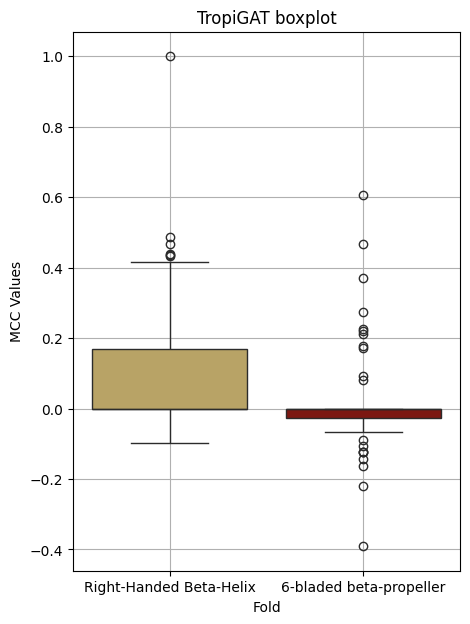

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Example data
data1 = mcc_helices_tropigat
data2 = mcc_prop_tropigat

# Combine data and corresponding labels
combined_data = np.concatenate([data1, data2])
labels = ['Right-Handed Beta-Helix'] * len(data1) + ['6-bladed beta-propeller'] * len(data2)

# Create box plot using Seaborn
plt.figure(figsize=(5, 7))
sns.boxplot(x=labels, y=combined_data, palette={'Right-Handed Beta-Helix': '#c6aa58ff', '6-bladed beta-propeller': '#8d0801ff'})

# Add labels and title
plt.xlabel('Fold')
plt.ylabel('MCC Values')
plt.title('TropiGAT boxplot')

# Show plot
plt.grid(True)
plt.savefig(f'{path_panels}/fold_box_plot.TropiGAT.reviewed.svg', dpi = 500)
plt.show()

In [31]:
len(mcc_helices_tropiseq), len(mcc_prop_tropiseq)

(87, 67)

/tmp/ipykernel_3505203/1771779139.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=labels, y=combined_data, palette={'Right-Handed Beta-Helix': '#c6aa58ff', '6-bladed beta-propeller': '#8d0801ff'})


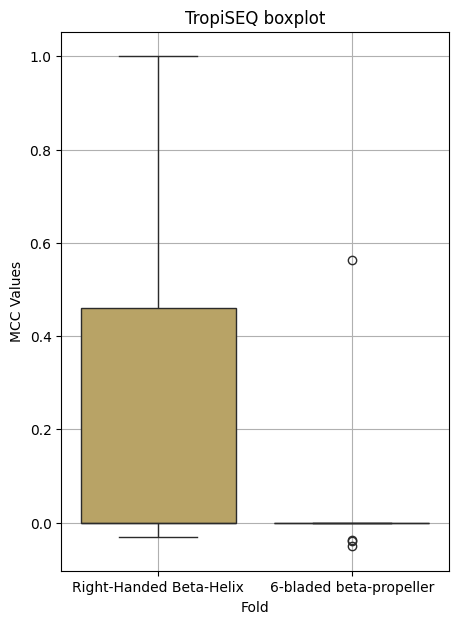

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Example data
data1 = mcc_helices_tropiseq
data2 = mcc_prop_tropiseq

# Combine data and corresponding labels
combined_data = np.concatenate([data1, data2])
labels = ['Right-Handed Beta-Helix'] * len(data1) + ['6-bladed beta-propeller'] * len(data2)

# Create box plot using Seaborn
plt.figure(figsize=(5, 7))
sns.boxplot(x=labels, y=combined_data, palette={'Right-Handed Beta-Helix': '#c6aa58ff', '6-bladed beta-propeller': '#8d0801ff'})

# Add labels and title
plt.xlabel('Fold')
plt.ylabel('MCC Values')
plt.title('TropiSEQ boxplot')

# Show plot
plt.grid(True)
plt.savefig(f'{path_panels}/fold_box_plot.TropiSEQ.reviewed.svg', dpi = 500)
plt.show()

In [194]:
len(get_MCC(tropigat_n_betaprop_df)) , len(get_MCC_raw(tropigat_helices_df))

nul = 0
positive = 0
negative = 0
nan = 0

for item in get_MCC_raw(tropigat_n_betaprop_df) :
    if isinstance(item , (int, float)) : 
        if item == 0.0 or item == 0 :
            nul += 1 
        elif item < 0 :
            negative += 1 
        else :
            positive += 1
    else : 
        nan += 1
            
nul , positive, negative, nan

(1, 49, 17, 0)

In [195]:
get_MCC_raw(tropigat_n_betaprop_df)

[-0.03537790870034883,
 -0.05227083734893167,
 nan,
 0.0,
 -0.22056438662814232,
 nan,
 nan,
 nan,
 nan,
 -0.16226969413320902,
 -0.3801726581436387,
 -0.06726727939963124,
 -0.03724856463036033,
 nan,
 -0.023769134427076417,
 0.27927927927927926,
 nan,
 -0.10397504898200727,
 -0.12289901003127189,
 0.1777046633277277,
 0.46637240216721393,
 nan,
 nan,
 0.09354143466934853,
 nan,
 nan,
 -0.07223151185146152,
 0.1720618004029213,
 nan,
 -0.12864083083132663,
 0.27399831217559545,
 nan,
 nan,
 nan,
 nan,
 nan,
 -0.03673591791853225,
 nan,
 nan,
 0.08006407690254357,
 0.3701780228629408,
 -0.12309149097933272,
 nan,
 0.6391263149222874,
 nan,
 nan,
 nan,
 -0.02564102564102564,
 0.2102722062854239,
 nan,
 nan,
 0.22487239817113244,
 nan,
 nan,
 -0.12361284651454937,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 -0.05,
 nan,
 nan]

In [221]:
[item for item in mcc_helices_tropigat if item >0 ]

[0.3303043991400771,
 0.14907119849998599,
 0.23949803205727466,
 0.24282146558931603,
 0.4334498677803327,
 0.3954372976473721,
 0.22681906103078386,
 0.24261672707004478,
 0.0825840139015334,
 0.2030905986149808,
 0.21966689613035442,
 0.43587300037912335,
 0.14862950508912245,
 0.487770465364315,
 0.12466910770584998,
 0.09133370363944028,
 0.06684480693860813,
 0.32582240849046523,
 0.15419152487578391,
 0.18038166015206336,
 0.09927337820337083,
 0.27773186030035396,
 0.17604469755488258,
 0.08703333689083328,
 0.2839372243904292,
 0.14184363653291035,
 0.16198789882296566,
 0.46825396825396826,
 0.30069184294819906,
 0.11619374420894563,
 0.41506984975750405,
 0.43852900965351466,
 0.375,
 1.0]

In [220]:
len([item for item in mcc_helices_tropigat if item >0 ])

34

In [176]:
round_number(mean(mcc_helices_tropigat)) , round_number(mean(mcc_helices_tropiseq)) , round_number(mean(mcc_prop_tropigat)) , round_number(mean(mcc_prop_tropiseq))

(0.16, 0.5, 0.04, 0.11)

In [217]:
len(mcc_prop_tropigat) , len(get_MCC_raw(tropigat_n_betaprop_df))

(29, 67)

In [213]:
mcc_prop_tropigat

[0.5623515948579824,
 -0.03857583749052298,
 -0.03673591791853225,
 -0.05057217374241736]

In [162]:
mcc_prop_tropiseq

[0.5623515948579824,
 -0.03857583749052298,
 -0.03673591791853225,
 -0.05057217374241736]

In [205]:
non_helice_results_df[non_helice_results_df["phage"] == "K41P2"]

,phage,protein,Folds,TropiGAT_new_UF_prediction,TropiGAT_new_UF_good_calls,TropiSEQ_prediction,TropiSEQ_good_calls,SpikeHunter_prediction,SpikeHunter_good_calls,Targets
132,K41P2,K41P2__cds_11,6-bladed beta-propeller,KL26:0.994 ; KL23:0.993 ; KL106:0.99 ; KL123:0...,KL39,KL60:0.486 ; KL37:0.235 ; KL164:0.195 ; KL61:0...,0,No_hits,0,"KL41,KL39"


In [211]:
non_helice_results_df

target_prop = []

for _, row in non_helice_results_df.iterrows() :
    target_prop = target_prop + row["Targets"].split(",")
    
len(set(target_prop))



67

In [201]:
Counter(non_helice_results_df["TropiSEQ_prediction"])

Counter({'KL102:0.737 ; KL7:0.448 ; KL37:0.235 ; KL164:0.195 ; KL61:0.188 ; KL109:0.183 ; KL66:0.182 ; KL143:0.179 ; KL11:0.178 ; KL113:0.178': 58,
         'KL60:0.486 ; KL37:0.235 ; KL164:0.195 ; KL61:0.188 ; KL109:0.183 ; KL66:0.182 ; KL143:0.179 ; KL11:0.178 ; KL113:0.178 ; KL137:0.173': 11,
         'No_hits': 4,
         'KL124:0.971 ; KL21:0.622 ; KL35:0.565 ; KL30:0.519 ; KL31:0.506 ; KL39:0.469 ; KL164:0.195 ; KL61:0.188 ; KL109:0.183 ; KL66:0.182': 1,
         'KL37:0.235 ; KL164:0.195 ; KL61:0.188 ; KL66:0.182 ; KL143:0.179 ; KL11:0.178 ; KL113:0.178 ; KL137:0.173 ; KL41:0.17 ; KL35:0.17': 1})

In [ ]:
# cluster 762 (58)
# cluster 274 (11)
# No_hits (4)

In [223]:
69/75

0.92

In [197]:
tropiseq_lytic_clusters = {'K10PH82C1__cds_49': 'No hits',
 'K13PH07C1L__cds_10': 'Dpo_cdhit_595',
 'K13PH07C1L__cds_11': 'Dpo_cdhit_62',
 'K13PH07C1L__cds_12': 'Dpo_cdhit_965',
 'K15PH90__cds_54': 'No hits',
 'K18PH07C1__cds_243': 'Dpo_cdhit_626',
 'K18PH07C1__cds_245': 'Dpo_cdhit_379',
 'K22PH164C1__cds_11': 'No hits',
 'K30lambda2_2__cds_152': 'No hits',
 'K30lambda2_2__cds_20': 'No hits',
 'K32PH164C1__cds_151': 'No hits',
 'K32PH164C1__cds_20': 'No hits',
 'K34PH164__cds_24': 'No hits',
 'K41P2__cds_227': 'No hits',
 'K49PH164C2__cds_24': 'No hits',
 'K65PH164__cds_198': 'No hits',
 'K70PH128C1__cds_24': 'No hits',
 'K7PH164C4__cds_151': 'No hits',
 'K7PH164C4__cds_20': 'No hits',
 'K17alfa62__cds_66_A_281-682': 'Dpo_cdhit_88',
 'K14PH164C1__cds_24_A_4_221_871.pdb': 'Dpo_cdhit_92',
 'K64PH164C4__cds_24_A_4_178_852.pdb': 'Dpo_cdhit_56',
 'K40PH129C1__cds_56_A_4_239_860.pdb': 'No hits',
 'K51PH129C1__cds_9_A_1_92_787.pdb': 'Dpo_cdhit_47',
 'K15PH90__cds_55_A.pdb': 'Dpo_cdhit_182',
 'K21lambda1__cds_28_A.pdb': 'Dpo_cdhit_336',
 'K26PH128C1__cds_50_A_1_97_595.pdb': 'Dpo_cdhit_87',
 'K35PH164C3__cds_48_A_4_282_728.pdb': 'Dpo_cdhit_352',
 'K37PH164C1__cds_47_A_1_1_307.pdb': 'Dpo_cdhit_599',
 'K38PH09C2__cds_24_A_4_178_672.pdb': 'Dpo_cdhit_76',
 'K27PH129C1__cds_48_A_7_200_648.pdb': 'Dpo_cdhit_268',
 'K5lambda5__cds_198_A_3_173_674.pdb': 'Dpo_cdhit_104',
 'K41P2__cds_11_A_7_188_506.pdb': 'Dpo_cdhit_274',
 'K43PH164C1__cds_40_A_3_296_718.pdb': 'Dpo_cdhit_311',
 'K11PH164C1__cds_46_A_1_1_416.pdb': 'Dpo_cdhit_429',
 'K17alfa62__cds_64_A_3_129_548.pdb': 'Dpo_cdhit_362',
 'K2PH164C1__cds_23_A_6_269_664.pdb': 'No hits',
 'K2alfa62__cds_23_A_6_269_671.pdb': 'No hits',
 'K56PH164C1__cds_48_A_5_293_702.pdb': 'No hits',
 'K82P1__cds_45_A_5_292_704.pdb': 'No hits',
 'K66PH128C1__cds_59_A_4_252_713.pdb': 'Dpo_cdhit_284',
 'K23PH08C2__cds_233_A_2_76_514.pdb': 'Dpo_cdhit_235',
 'K60PH164C1__cds_96_A_6_321_703.pdb': 'Dpo_cdhit_9',
 'K56PH164C1__cds_49_A_3_110_475.pdb': 'Dpo_cdhit_295',
 'K74PH129C2__cds_52_A_2_34_431.pdb': 'Dpo_cdhit_391',
 'K8PH128__cds_46_A_5_294_719.pdb': 'No hits',
 'K44PH129C1__cds_9_A_2_39_391.pdb': 'Dpo_cdhit_599',
 'K22PH164C1__cds_10_A_1_1_368.pdb': 'Dpo_cdhit_599',
 'K24PH164C1__cds_8_A_2_85_402.pdb': 'Dpo_cdhit_71',
 'K48PH164C1__cds_49_A_3_306_628.pdb': 'Dpo_cdhit_261',
 'K25PH129C1__cds_60_A_5_311_671.pdb': 'Dpo_cdhit_487',
 'K39PH122C2__cds_55_A_5_286_658.pdb': 'Dpo_cdhit_421',
 'K39PH122C2__cds_8_A_4_33_387.pdb': 'Dpo_cdhit_595',
 'K13PH07C1S__cds_10_A_7_32_375.pdb': 'Dpo_cdhit_595',
 'K61PH164C1__cds_9_A_1_1_387.pdb': 'Dpo_cdhit_513',
 'K46PH129__cds_24_A_8_222_596.pdb': 'Dpo_cdhit_269',
 'K60PH164C1__cds_94_A_3_119_467.pdb': 'Dpo_cdhit_528',
 'K5lambda5__cds_196_A_4_457_808.pdb': 'Dpo_cdhit_528',
 'K43PH164C1__cds_41_A_3_32_385.pdb': 'Dpo_cdhit_528',
 'K57lambda1_2__cds_92_A_3_120_506.pdb': 'Dpo_cdhit_429',
 'K61PH164C1__cds_10_A_3_80_443.pdb': 'Dpo_cdhit_508',
 'K71PH129C1__cds_55_A_5_295_682.pdb': 'Dpo_cdhit_389',
 'K45PH128C2__cds_237_A_3_76_463.pdb': 'Dpo_cdhit_389',
 'K80PH1317b__cds_54_A_2_36_354.pdb': 'Dpo_cdhit_639',
 'K80PH1317a__cds_54_A_2_36_354.pdb': 'Dpo_cdhit_639',
 'K82P1__cds_46_A_2_94_449.pdb': 'Dpo_cdhit_488',
 'K11PH164C1__cds_45_A_5_356_700.pdb': 'Dpo_cdhit_464',
 'K45PH128C2__cds_239_A_1_186_411.pdb': 'Dpo_cdhit_884',
 'K4PH164__cds_22_A_1_53_402.pdb': 'Dpo_cdhit_730',
 'K53PH164C2__cds_24_A_4_200_777.pdb': 'Dpo_cdhit_58',
 'K54lambda1_1_1__cds_238_A_1_78_646.pdb': 'Dpo_cdhit_120',
 'K57lambda1_2__cds_93_A_4_251_900.pdb': 'Dpo_cdhit_230',
 'K58PH129C2__cds_47_A_2_38_516.pdb': 'Dpo_cdhit_188',
 'K16PH164C3__cds_48_A_3_292_776.pdb': 'Dpo_cdhit_231',
 'K17alfa61__cds_23_A_4_179_630.pdb': 'No hits',
 'K1PH164C1__cds_8_A_2_69_559.pdb': 'No hits',
 'K44PH129C1__cds_10_A_3_35_538.pdb': 'Dpo_cdhit_190',
 'K63PH128__cds_22_A_5_260_714.pdb': 'Dpo_cdhit_303',
 'K5lambda5__cds_199_A_2_109_658.pdb': 'No hits',
 'K10PH82C1__cds_50_A_5_301_819.pdb': 'No hits',
 'K74PH129C2__cds_51_A_3_291_808.pdb': 'Dpo_cdhit_14',
 'K26PH128C1__cds_49_A_3_291_808.pdb': 'Dpo_cdhit_14',
 'K65PH164__cds_12_A_5_181_627.pdb': 'Dpo_cdhit_274',
 'K6PH25C3__cds_23_A_3_206_691.pdb': 'Dpo_cdhit_198',
 'K80PH1317a__cds_52_A_5_302_576.pdb': 'Dpo_cdhit_246',
 'K80PH1317a__cds_53_A.pdb': 'Dpo_cdhit_14',
 'K80PH1317b__cds_52_A_5_302_606.pdb': 'Dpo_cdhit_246',
 'K2PH164C2__cds_24_A_6_274_608.pdb': 'Dpo_cdhit_625',
 'K10PH82C1__cds_51_A_2_38_368.pdb': 'Dpo_cdhit_611',
 'K13PH07C1S__cds_11_A_2_93_430.pdb': 'Dpo_cdhit_521',
 'K37PH164C1__cds_48_A_2_37_367.pdb': 'Dpo_cdhit_521',
 'K54lambda2__cds_23_A_7_214_582.pdb': 'No hits',
 'K5lambda5__cds_200_A_2_111_443.pdb': 'Dpo_cdhit_180',
 'K80PH1317b__cds_53_A.pdb': 'Dpo_cdhit_14',
 'K10PH82C1 cds_45': 'Dpo_cdhit_762',
 'K11PH164C1 cds_39': 'Dpo_cdhit_762',
 'K12P1_1 cds_43': 'Dpo_cdhit_762',
 'K13PH07C1L cds_54': 'Dpo_cdhit_762',
 'K13PH07C1S cds_53': 'Dpo_cdhit_762',
 'K15PH90 cds_49': 'Dpo_cdhit_762',
 'K16PH164C3 cds_43': 'Dpo_cdhit_762',
 'K19PH14C4P1 cds_43': 'Dpo_cdhit_762',
 'K1PH164C1 cds_53': 'Dpo_cdhit_762',
 'K2069PH1 cds_25': 'No hits',
 'K22PH164C1 cds_50': 'Dpo_cdhit_762',
 'K24PH164C1 cds_55': 'Dpo_cdhit_762',
 'K25PH129C1 cds_56': 'Dpo_cdhit_762',
 'K26PH128C1 cds_44': 'Dpo_cdhit_762',
 'K27PH129C1 cds_43': 'Dpo_cdhit_762',
 'K35PH164C3 cds_43': 'Dpo_cdhit_762',
 'K37PH164C1 cds_41': 'Dpo_cdhit_762',
 'K39PH122C2 cds_50': 'Dpo_cdhit_762',
 'K40PH129C1 cds_52': 'Dpo_cdhit_762',
 'K42PH8 cds_43': 'Dpo_cdhit_762',
 'K42PH8 cds_48': 'Dpo_cdhit_144',
 'K43PH164C1 cds_35': 'Dpo_cdhit_762',
 'K44PH129C1 cds_45': 'Dpo_cdhit_762',
 'K48PH164C1 cds_43': 'Dpo_cdhit_762',
 'K51PH129C1 cds_56': 'Dpo_cdhit_762',
 'K56PH164C1 cds_43': 'Dpo_cdhit_762',
 'K58PH129C2 cds_40': 'Dpo_cdhit_762',
 'K59PH2 cds_46': 'Dpo_cdhit_762',
 'K61PH164C1 cds_52': 'Dpo_cdhit_762',
 'K66PH128C1 cds_55': 'Dpo_cdhit_762',
 'K71PH129C1 cds_51': 'Dpo_cdhit_762',
 'K72PH164C2 cds_51': 'Dpo_cdhit_762',
 'K74PH129C2 cds_46': 'Dpo_cdhit_762',
 'K80PH1317a cds_47': 'Dpo_cdhit_762',
 'K80PH1317b cds_47': 'Dpo_cdhit_762',
 'K82P1 cds_40': 'Dpo_cdhit_762',
 'K8PH128 cds_41': 'Dpo_cdhit_762',
 'K72PH164C2 cds_55': 'Dpo_cdhit_243',
 'K33PH14C2 cds_55': 'No hits',
 'K33PH14C2 cds_25': 'No hits',
 'K31PH164 cds_25': 'No hits',
 'K52PH129C1 cds_25': 'No hits',
 'K69PH164C2 cds_24': 'No hits',
 'K28PH129 cds_24': 'No hits',
 'K2064PH2 cds_25': 'No hits',
 'K19PH14C4P1 cds_48': 'No hits',
 'K50PH164C1 cds_28': 'No hits',
 'K29PH164C1 cds_25': 'No hits',
 'K62PH164C2 cds_25': 'No hits',
 'K9PH25C2 cds_76': 'Dpo_cdhit_775',
 'EHPPICDA_00095': 'Dpo_cdhit_274',
 'DIMCIIMF_00039': 'No hits',
 'DIMCIIMF_00240': 'Dpo_cdhit_274',
 'OBHDAGOG_00029': 'No hits',
 'LCALLHIG_00050': 'Dpo_cdhit_319',
 'HIIECEMK_00043': 'Dpo_cdhit_762',
 'HIIECEMK_00054': 'Dpo_cdhit_62',
 'GCLPFEGH_00240': 'Dpo_cdhit_274',
 'IPGJFKPH_00198': 'Dpo_cdhit_274',
 'POFPNCPI_00246': 'Dpo_cdhit_274',
 'INMBNBLA_00138': 'Dpo_cdhit_274',
 'INMBNBLA_00202': 'No hits',
 'OPBIHMGG_00067': 'Dpo_cdhit_319',
 'BLCJPOBP_00041': 'Dpo_cdhit_762',
 'FADJDIKG_00019': 'No hits',
 'FADJDIKG_00083': 'Dpo_cdhit_274',
 'PP187_gp225': 'Dpo_cdhit_232',
 'PP187_gp227': 'Dpo_cdhit_355',
 'PP187_gp230': 'Dpo_cdhit_764',
 'PP187_gp233': 'Dpo_cdhit_652',
 'PP187_gp235': 'Dpo_cdhit_611',
 'PP187_gp237': 'Dpo_cdhit_272',
 'PP187_gp239': 'Dpo_cdhit_231',
 'KBDEFBCI_00052': 'Dpo_cdhit_352',
 'KBDEFBCI_00054': 'Dpo_cdhit_421',
 'KBDEFBCI_00056': 'Dpo_cdhit_179',
 'KBDEFBCI_00058': 'Dpo_cdhit_413',
 'LLOFRUDD_00039': 'No hits',
 'DJLANJJD_00238': 'Dpo_cdhit_274',
 'NEBGPKAL_00001': 'No hits',
 'NEBGPKAL_00013': 'Dpo_cdhit_762',
 'EKPIEFBL_00113': 'No hits',
 'EKPIEFBL_00177': 'Dpo_cdhit_274',
 'EONHMLJF_00087': 'No hits',
 'NJHLHPIG_00055': 'Dpo_cdhit_352',
 'NJHLHPIG_00057': 'Dpo_cdhit_421',
 'NJHLHPIG_00059': 'No hits',
 'NJHLHPIG_00061': 'Dpo_cdhit_413',
 'PFOEGONH_00078': 'Dpo_cdhit_319',
 'NBNDMPCG_00161': 'Dpo_cdhit_352',
 'NBNDMPCG_00163': 'Dpo_cdhit_589',
 'NBNDMPCG_00165': 'No hits',
 'NBNDMPCG_00166': 'Dpo_cdhit_53',
 'NBNDMPCG_00168': 'Dpo_cdhit_375',
 'S13c_00055': 'Dpo_cdhit_106',
 'S10a_00097': 'Dpo_cdhit_406',
 'A1o_00041': 'Dpo_cdhit_762',
 'A1o_00045': 'Dpo_cdhit_421',
 'A1c_00034': 'No hits',
 'A1c_00046': 'Dpo_cdhit_762',
 'A1d_00009': 'Dpo_cdhit_213',
 'A1d_00013': 'Dpo_cdhit_762',
 'A1q_00010': 'Dpo_cdhit_676',
 'A1q_00019': 'Dpo_cdhit_421',
 'A1q_00023': 'Dpo_cdhit_762',
 'A1r_00009': 'Dpo_cdhit_421',
 'A1r_00013': 'Dpo_cdhit_762',
 'P4a_00011': 'Dpo_cdhit_635',
 'P4a_00013': 'Dpo_cdhit_306',
 'A1f_00012': 'Dpo_cdhit_71',
 'A1f_00024': 'Dpo_cdhit_762',
 'A1g_00045': 'Dpo_cdhit_762',
 'A1g_00057': 'No hits',
 'A3b_00016': 'Dpo_cdhit_762',
 'A3b_00021': 'Dpo_cdhit_594',
 'A1j_00002': 'Dpo_cdhit_762',
 'A1j_00040': 'Dpo_cdhit_31',
 'A1j_00049': 'Dpo_cdhit_82',
 'A2a_00010': 'Dpo_cdhit_762',
 'A2a_00049': 'Dpo_cdhit_31',
 'A1m_00045': 'Dpo_cdhit_762',
 'A1m_00049': 'Dpo_cdhit_421',
 'D7b_00043': 'Dpo_cdhit_547',
 'A1n_00050': 'Dpo_cdhit_762',
 'A1p_00055': 'Dpo_cdhit_762',
 'A3d_00036': 'Dpo_cdhit_762',
 'A3d_00041': 'Dpo_cdhit_43',
 'A3d_00042': 'Dpo_cdhit_513',
 'S13a_00036': 'Dpo_cdhit_441',
 'A3c_00039': 'Dpo_cdhit_762',
 'A3c_00044': 'Dpo_cdhit_464',
 'A3c_00045': 'Dpo_cdhit_513',
 'A1l_00005': 'Dpo_cdhit_762',
 'A1l_00058': 'Dpo_cdhit_954',
 'A3a_00002': 'Dpo_cdhit_38',
 'A3a_00045': 'Dpo_cdhit_762',
 'A2b_00008': 'Dpo_cdhit_31',
 'A2b_00022': 'Dpo_cdhit_762',
 'M5a_00170': 'Dpo_cdhit_286',
 'M5a_00175': 'No hits',
 'A1b_00036': 'Dpo_cdhit_762',
 'A1b_00048': 'Dpo_cdhit_61',
 'A1e_00012': 'Dpo_cdhit_71',
 'A1e_00024': 'Dpo_cdhit_762',
 'S11a_00036': 'Dpo_cdhit_406',
 'A1a_00002': 'Dpo_cdhit_762',
 'A1a_00014': 'Dpo_cdhit_508',
 'P4b_00023': 'Dpo_cdhit_306',
 'P4b_00025': 'Dpo_cdhit_635',
 'S13e_00021': 'Dpo_cdhit_297',
 'S13d_00057': 'Dpo_cdhit_53',
 'A1h_00009': 'Dpo_cdhit_762',
 'A1h_00013': 'Dpo_cdhit_501',
 'A1h_00021': 'Dpo_cdhit_586',
 'A1k_00014': 'Dpo_cdhit_421',
 'A1k_00018': 'Dpo_cdhit_762',
 'D7c_00007': 'Dpo_cdhit_73',
 'S13b_00058': 'Dpo_cdhit_303',
 'M5b_00086': 'Dpo_cdhit_479',
 'M12a_00031': 'Dpo_cdhit_468',
 'A2a_b_00022': 'Dpo_cdhit_31',
 'A2a_b_00036': 'Dpo_cdhit_762',
 'A1i_00037': 'Dpo_cdhit_762',
 'A1i_00041': 'Dpo_cdhit_501',
 'A1i_00049': 'Dpo_cdhit_31'}

In [199]:
cluters_lytoc = [value for key, value in tropiseq_lytic_clusters.items()]
Counter(cluters_lytoc)

Counter({'Dpo_cdhit_762': 63,
         'No hits': 50,
         'Dpo_cdhit_274': 11,
         'Dpo_cdhit_421': 8,
         'Dpo_cdhit_31': 5,
         'Dpo_cdhit_352': 4,
         'Dpo_cdhit_14': 4,
         'Dpo_cdhit_595': 3,
         'Dpo_cdhit_599': 3,
         'Dpo_cdhit_71': 3,
         'Dpo_cdhit_513': 3,
         'Dpo_cdhit_528': 3,
         'Dpo_cdhit_319': 3,
         'Dpo_cdhit_62': 2,
         'Dpo_cdhit_429': 2,
         'Dpo_cdhit_508': 2,
         'Dpo_cdhit_389': 2,
         'Dpo_cdhit_639': 2,
         'Dpo_cdhit_464': 2,
         'Dpo_cdhit_231': 2,
         'Dpo_cdhit_303': 2,
         'Dpo_cdhit_246': 2,
         'Dpo_cdhit_611': 2,
         'Dpo_cdhit_521': 2,
         'Dpo_cdhit_413': 2,
         'Dpo_cdhit_53': 2,
         'Dpo_cdhit_406': 2,
         'Dpo_cdhit_635': 2,
         'Dpo_cdhit_306': 2,
         'Dpo_cdhit_501': 2,
         'Dpo_cdhit_965': 1,
         'Dpo_cdhit_626': 1,
         'Dpo_cdhit_379': 1,
         'Dpo_cdhit_88': 1,
         'Dpo_cdhit_92'

In [142]:
tropigat_helices_df

,KL type,Count,F1,Accuracy,Recall,Precision,AUC,MCC
0,KL1,3,0.0,0.960000,0.000000,0.000000,0.494845,-0.017675
1,KL2,11,0.4,0.868421,0.454545,0.357143,0.683583,0.330304
2,KL3,7,0.5,0.571429,0.428571,0.600000,0.571429,0.149071
3,KL4,2,0.0,0.790123,0.000000,0.000000,0.405063,-0.075853
4,KL5,1,0.0,0.925373,0.000000,0.000000,0.469697,-0.031016
...,...,...,...,...,...,...,...,...
83,KL140,3,NaN,NaN,NaN,NaN,NaN,NaN
85,KL149,2,0.0,0.818182,0.000000,0.000000,0.435484,-0.094333
86,KL151,1,NaN,NaN,NaN,NaN,NaN,NaN
87,KL157,1,1.0,1.000000,1.000000,1.000000,1.000000,1.000000


In [143]:
tropiseq_helices_df

,KL type,Count,F1,Accuracy,Recall,Precision,AUC,MCC
0,KL1,3,NaN,NaN,NaN,NaN,NaN,NaN
1,KL2,11,0.428571,0.929825,0.272727,1.0,0.636364,0.503062
2,KL3,7,0.600000,0.714286,0.428571,1.0,0.714286,0.522233
3,KL4,2,NaN,NaN,NaN,NaN,NaN,NaN
4,KL5,1,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
83,KL140,3,NaN,NaN,NaN,NaN,NaN,NaN
85,KL149,2,NaN,NaN,NaN,NaN,NaN,NaN
86,KL151,1,1.000000,1.000000,1.000000,1.0,1.000000,1.000000
87,KL157,1,NaN,NaN,NaN,NaN,NaN,NaN


In [168]:
list(zip(tropiseq_betaprop_df["KL type"], tropiseq_betaprop_df["MCC"]))

tropiseq_betaprop_df[tropiseq_betaprop_df["KL type"] == "KL21"]

,KL type,Count,F1,Accuracy,Recall,Precision,AUC,MCC
20,KL21,3,0.5,0.95,0.333333,1.0,0.666667,0.562352


In [170]:
list(zip(tropigat_n_betaprop_df["KL type"], tropigat_n_betaprop_df["MCC"]))


[('KL1', -0.03537790870034883),
 ('KL2', -0.05227083734893167),
 ('KL3', nan),
 ('KL4', 0.0),
 ('KL7', -0.22056438662814232),
 ('KL8', nan),
 ('KL10', nan),
 ('KL11', nan),
 ('KL12', nan),
 ('KL13', -0.16226969413320902),
 ('KL14', -0.3801726581436387),
 ('KL15', -0.06726727939963124),
 ('KL16', -0.03724856463036033),
 ('KL19', nan),
 ('KL20', -0.023769134427076417),
 ('KL21', 0.27927927927927926),
 ('KL22', nan),
 ('KL24', -0.10397504898200727),
 ('KL25', -0.12289901003127189),
 ('KL26', 0.1777046633277277),
 ('KL27', 0.46637240216721393),
 ('KL28', nan),
 ('KL29', nan),
 ('KL30', 0.09354143466934853),
 ('KL31', nan),
 ('KL32', nan),
 ('KL35', -0.07223151185146152),
 ('KL36', 0.1720618004029213),
 ('KL37', nan),
 ('KL38', -0.12864083083132663),
 ('KL39', 0.27399831217559545),
 ('KL40', nan),
 ('KL41', nan),
 ('KL42', nan),
 ('KL43', nan),
 ('KL44', nan),
 ('KL47', -0.03673591791853225),
 ('KL48', nan),
 ('KL50', nan),
 ('KL51', 0.08006407690254357),
 ('KL52', 0.3701780228629408),
 ('K

In [173]:
tropigat_n_betaprop_df[tropigat_n_betaprop_df["KL type"] == "KL57"]

,KL type,Count,F1,Accuracy,Recall,Precision,AUC,MCC
56,KL57,9,0.695652,0.865385,0.888889,0.571429,0.874677,0.639126


In [ ]:
comparative_helices_df = pd.DataFrame({
            "KL type": tropigat_helices_df["KL type"],
            "Count": tropigat_helices_df["Count"],
            # recall
            "Recall_TropiGAT": tropigat_helices_df["Recall"].round(3),
            "Recall_TropiSEQ": tropiseq_helices_df["Recall"].round(3),
            "Recall_TropiSH": tropish_helices_df["Recall"].round(3),
            # precision: 
            "Precision_TropiGAT": tropigat_helices_df["Precision"].round(3),
            "Precision_TropiSEQ": tropiseq_helices_df["Precision"].round(3),
            "Precision_TropiSH": tropish_helices_df["Precision"].round(3),
            # MCC: 
            "MCC_TropiGAT": tropigat_helices_df["MCC"].round(3),
            "MCC_TropiSEQ": tropiseq_helices_df["MCC"].round(3),
            "MCC_TropiSH": tropish_helices_df["MCC"].round(3),
        })

comparative_helices_df = comparative_helices_df.fillna("-")
comparative_helices_df.to_csv(f"{path_benchmark}/Comparative.Helices.tsv", sep = "\t", index = False, header = True)

In [ ]:
comparative_helices_df

***
### Experimentally validated depolymerase results: 

In [2]:
# regular filtration: 
#tropigat_pred_xp_df = pd.read_csv(f"{path_benchmark}/TropiGAT.exp_val_depolymerase.tsv", sep = "\t", names = ["protein", "TropiGAT_prediction"])
tropigat_new_pred_xp_df = pd.read_csv(f"{path_benchmark}/TropiGAT_new.review.exp_val_depolymerase.tsv", sep = "\t", names = ["protein", "TropiGAT_new_prediction"])
#tropigat_no_heads_pred_xp_df = pd.read_csv(f"{path_benchmark}/TropiGAT_no_heads.review.exp_val_depolymerase.tsv", sep = "\t", names = ["protein", "TropiGAT_no_heads_prediction"])


tropisage_pred_xp_df = pd.read_csv(f"{path_benchmark}/TropiSAGE.review.exp_val_depolymerase.tsv", sep = "\t", names = ["protein", "TropiSAGE_prediction"])

tropiseq_pred_xp_df = pd.read_csv(f"{path_benchmark}/TropiSEQ.p_05.exp_val_depolymerase.tsv", sep = "\t", names = ["protein", "TropiSEQ_prediction"])
tropilr_pred_xp_df = pd.read_csv(f"{path_benchmark}/TropiLogReg.exp_val_depolymerase.tsv", sep = "\t", names = ["protein", "TropiLR_prediction"])

# Ultra filtration: 
tropigat_new_pred_xp_df_uf = pd.read_csv(f"{path_benchmark}/TropiGAT_new_UF.review.exp_val_depolymerase.tsv", sep = "\t", names = ["protein", "TropiGAT_UF_prediction"])
tropisage_pred_xp_df_uf = pd.read_csv(f"{path_benchmark}/TropiSAGE_UF.review.exp_val_depolymerase.tsv", sep = "\t", names = ["protein", "TropiSAGE_UF_prediction"])

tropiseq_pred_xp_df_uf = pd.read_csv(f"{path_benchmark}/TropiSEQ_UF_70.p_05.exp_val_depolymerase.tsv", sep = "\t", names = ["protein", "TropiSEQ_UF_prediction"])
#tropilr_pred_xp_df = pd.read_csv(f"{path_benchmark}/TropiLogReg.exp_val_depolymerase.tsv", sep = "\t", names = ["protein", "prediction"])

# SpikeHunter
SH_pred_xp_df = pd.read_csv(f"{path_benchmark}/SpikeHunter_predictions.exp_val_depolymerase.tsv", sep = "\t", names = ["protein", "SpikeHunter_prediction"])
SH_pred_xp_df["SpikeHunter_prediction"] = SH_pred_xp_df["SpikeHunter_prediction"].apply(lambda x : x.replace("K", "KL"))


> Add metadata: 

In [2]:
info_depo = pd.read_csv(f"{path_benchmark}/exp_val_depolymerase.tsv", sep = "\t", header = 0)


In [4]:
#merged_df = tropigat_pred_xp_df.merge(tropigat_new_pred_xp_df, on='protein', how='inner').merge(tropisage_pred_xp_df, on='protein', how='inner').merge(tropiseq_pred_xp_df, on='protein', how='inner').merge(tropigat_new_pred_xp_df_uf, on='protein', how='inner').merge(tropisage_pred_xp_df_uf, on='protein', how='inner').merge(tropiseq_pred_xp_df_uf, on='protein', how='inner').merge(SH_pred_xp_df, on='protein', how='inner').merge(tropigat_no_heads_pred_xp_df, on='protein', how='inner').merge(tropilr_pred_xp_df, on='protein', how='inner')
#merged_df = tropigat_pred_xp_df.merge(tropigat_new_pred_xp_df, on='protein', how='inner').merge(tropisage_pred_xp_df, on='protein', how='inner').merge(tropiseq_pred_xp_df, on='protein', how='inner').merge(tropigat_new_pred_xp_df_uf, on='protein', how='inner').merge(tropisage_pred_xp_df_uf, on='protein', how='inner').merge(tropiseq_pred_xp_df_uf, on='protein', how='inner').merge(SH_pred_xp_df, on='protein', how='inner').merge(tropilr_pred_xp_df, on='protein', how='inner')
#merged_df = tropigat_new_pred_xp_df.merge(tropisage_pred_xp_df, on='protein', how='inner').merge(tropiseq_pred_xp_df, on='protein', how='inner').merge(tropigat_new_pred_xp_df_uf, on='protein', how='inner').merge(tropisage_pred_xp_df_uf, on='protein', how='inner').merge(tropiseq_pred_xp_df_uf, on='protein', how='inner').merge(SH_pred_xp_df, on='protein', how='inner').merge(tropilr_pred_xp_df, on='protein', how='inner')

merged_df = tropigat_new_pred_xp_df.merge(tropisage_pred_xp_df, on='protein', how='inner').merge(tropiseq_pred_xp_df, on='protein', how='inner').merge(tropigat_new_pred_xp_df_uf, on='protein', how='inner').merge(tropisage_pred_xp_df_uf, on='protein', how='inner').merge(tropiseq_pred_xp_df_uf, on='protein', how='inner').merge(SH_pred_xp_df, on='protein', how='inner').merge(tropilr_pred_xp_df, on='protein', how='inner')


missing_protein = merged_df[~merged_df["protein"].isin(list(info_depo["protein"]))]["protein"]
merged_df = merged_df[merged_df["protein"].isin(list(info_depo["protein"]))]
target_col = []
phage_col = []

for _, row in merged_df.iterrows() :
    try : 
        target_col.append(info_depo[info_depo["protein"] == row["protein"]]["Target"].values[0])
        phage_col.append(info_depo[info_depo["protein"] == row["protein"]]["Phage"].values[0])
    except IndexError :
        print(row["protein"])


merged_df["Target"] = target_col
merged_df["Phage"] = phage_col




In [5]:
merged_df

len(merged_df)

34

In [6]:
merged_df[merged_df["protein"] == "APZ82768__116_426"]["TropiGAT_UF_prediction"].values

array(['KL18:0.931 ; KL2:0.916 ; KL60:0.89 ; KL45:0.874 ; KL155:0.832 ; KL71:0.825 ; KL122:0.758 ; KL10:0.666 ; KL30:0.46 ; KL35:0.395 ; KL116:0.38 ; KL9:0.343 ; KL36:0.307 ; KL34:0.291 ; KL3:0.241 ; KL151:0.226 ; KL105:0.18 ; KL23:0.172 ; KL20:0.165 ; KL5:0.149 ; KL169:0.146 ; KL64:0.129 ; KL153:0.12 ; KL1:0.093 ; KL56:0.063 ; KL63:0.041 ; KL43:0.04 ; KL46:0.039 ; KL117:0.038 ; KL4:0.035 ; KL109:0.035 ; KL128:0.029 ; KL31:0.028 ; KL15:0.027 ; KL48:0.024 ; KL149:0.022 ; KL26:0.02 ; KL19:0.018 ; KL124:0.018 ; KL67:0.015 ; KL110:0.013 ; KL25:0.013 ; KL14:0.011 ; KL81:0.01 ; KL106:0.01 ; KL8:0.01 ; KL103:0.008 ; KL112:0.008 ; KL13:0.008 ; KL142:0.008 ; KL136:0.007 ; KL157:0.005 ; KL55:0.005 ; KL102:0.005 ; KL52:0.004 ; KL51:0.004 ; KL111:0.004 ; KL17:0.004 ; KL24:0.004 ; KL28:0.004 ; KL27:0.003 ; KL127:0.003 ; KL16:0.003 ; KL145:0.003 ; KL12:0.003 ; KL74:0.002 ; KL39:0.002 ; KL114:0.002 ; KL6:0.002 ; KL47:0.002 ; KL108:0.002 ; KL125:0.001 ; KL118:0.001 ; KL107:0.001 ; KL70:0.001 ; KL21:0.

In [7]:

merged_df

,protein,TropiGAT_new_prediction,TropiSAGE_prediction,TropiSEQ_prediction,TropiGAT_UF_prediction,TropiSAGE_UF_prediction,TropiSEQ_UF_prediction,SpikeHunter_prediction,TropiLR_prediction,Target,Phage
0,AB716666.1_prot_BAP15736.1_24,KL19:0.991 ; KL41:0.851 ; KL153:0.749 ; KL6:0....,KL7:0.998 ; KL123:0.995 ; KL14:0.986 ; KL118:0...,KL102:0.737 ; KL7:0.448 ; KL37:0.235 ; KL164:0...,KL123:0.999 ; KL4:0.996 ; KL55:0.987 ; KL14:0....,KL14:1.0 ; KL123:1.0 ; KL4:0.999 ; KL43:0.991 ...,KL102:0.996 ; KL7:0.942 ; KL6:0.213 ; KL4:0.16...,No_hits,No_associations,ND,Klebsiella phage NTUH-K2044-K1-1
1,AB716666.1_prot_BAP15746.1_34,KL128:0.997 ; KL47:0.985 ; KL21:0.984 ; KL70:0...,KL128:1.0 ; KL31:1.0 ; KL21:0.999 ; KL70:0.998...,No_hits,KL128:0.99 ; KL43:0.955 ; KL21:0.899 ; KL34:0....,KL34:0.999 ; KL140:0.996 ; KL62:0.994 ; KL9:0....,No_hits,No_hits,No_hits,K1,Klebsiella phage NTUH-K2044-K1-1
2,AB897757.1_prot_BAQ02835.1_55,KL123:0.848 ; KL46:0.811 ; KL152:0.689 ; KL70:...,KL53:0.984 ; KL123:0.976 ; KL152:0.934 ; KL9:0...,KL124:0.486 ; KL37:0.235 ; KL164:0.195 ; KL61:...,KL46:0.952 ; KL64:0.746 ; KL26:0.709 ; KL27:0....,KL109:1.0 ; KL36:0.988 ; KL149:0.918 ; KL103:0...,KL124:0.649 ; KL6:0.213 ; KL4:0.168 ; KL117:0....,O1,No_associations,K11*,Klebsiella Phage ΦK64-1
3,AB897757.1_prot_BAQ02836.1_56,KL70:0.983 ; KL52:0.974 ; KL12:0.972 ; KL26:0....,KL70:1.0 ; KL26:0.999 ; KL125:0.981 ; KL35:0.9...,KL70:0.888 ; KL21:0.674 ; KL149:0.43 ; KL37:0....,KL26:0.832 ; KL118:0.753 ; KL169:0.679 ; KL127...,KL109:0.997 ; KL26:0.977 ; KL149:0.957 ; KL103...,KL70:0.983 ; KL149:0.408 ; KL21:0.22 ; KL6:0.2...,KL21,KL70:0.898,KN4†,Klebsiella Phage ΦK64-1
4,AB897757.1_prot_BAQ02837.1_57,KL128:0.993 ; KL70:0.928 ; KL81:0.748 ; KL139:...,KL19:0.997 ; KL70:0.996 ; KL128:0.994 ; KL153:...,KL123:0.711 ; KL37:0.235 ; KL164:0.195 ; KL61:...,KL71:0.916 ; KL151:0.908 ; KL26:0.846 ; KL81:0...,KL26:0.999 ; KL151:0.998 ; KL109:0.991 ; KL103...,KL6:0.213 ; KL4:0.168 ; KL117:0.168 ; KL51:0.1...,"KL123 , KL60",KL123:0.632,K21*,Klebsiella Phage ΦK64-1
5,AB897757.1_prot_BAQ02838.1_58,KL152:0.989 ; KL12:0.986 ; KL109:0.973 ; KL52:...,KL152:1.0 ; KL109:0.999 ; KL142:0.997 ; KL70:0...,No_hits,KL151:0.989 ; KL26:0.968 ; KL109:0.841 ; KL118...,KL128:1.0 ; KL151:1.0 ; KL142:0.998 ; KL26:0.9...,No_hits,No_hits,No_hits,KN5*,Klebsiella Phage ΦK64-1
6,AB897757.1_prot_BAQ02839.1_59,KL111:0.875 ; KL16:0.376 ; KL70:0.362 ; KL24:0...,KL111:0.979 ; KL29:0.977 ; KL18:0.893 ; KL19:0...,KL37:0.235 ; KL164:0.195 ; KL61:0.188 ; KL109:...,KL10:0.98 ; KL24:0.801 ; KL26:0.779 ; KL64:0.6...,KL26:0.999 ; KL109:0.997 ; KL10:0.996 ; KL111:...,KL25:0.496 ; KL6:0.213 ; KL4:0.168 ; KL117:0.1...,KL25,No_associations,K25†,Klebsiella Phage ΦK64-1
7,AB897757.1_prot_BAQ02840.1_60,KL36:1.0 ; KL19:0.975 ; KL52:0.967 ; KL152:0.9...,KL152:1.0 ; KL36:0.999 ; KL35:0.998 ; KL19:0.9...,KL35:0.66 ; KL37:0.235 ; KL164:0.195 ; KL61:0....,KL122:0.981 ; KL118:0.979 ; KL151:0.958 ; KL46...,KL128:1.0 ; KL36:0.999 ; KL26:0.999 ; KL151:0....,KL35:0.414 ; KL6:0.213 ; KL4:0.168 ; KL117:0.1...,KL35,No_associations,K35†,Klebsiella Phage ΦK64-1
8,AB897757.1_prot_BAQ02841.1_61,KL169:0.998 ; KL47:0.979 ; KL152:0.927 ; KL35:...,KL169:1.0 ; KL152:0.996 ; KL47:0.957 ; KL64:0....,No_hits,KL14:0.905 ; KL109:0.871 ; KL81:0.845 ; KL169:...,KL47:1.0 ; KL109:0.999 ; KL81:0.993 ; KL26:0.9...,No_hits,No_hits,No_hits,K1*,Klebsiella Phage ΦK64-1
9,AB897757.1_prot_BAQ02842.1_62,KL152:0.919 ; KL18:0.864 ; KL57:0.805 ; KL22:0...,KL152:1.0 ; KL112:1.0 ; KL14:0.994 ; KL18:0.99...,KL64:0.904 ; KL37:0.235 ; KL164:0.195 ; KL61:0...,KL26:0.986 ; KL64:0.984 ; KL151:0.966 ; KL109:...,KL155:1.0 ; KL103:1.0 ; KL64:1.0 ; KL109:1.0 ;...,KL64:0.374 ; KL6:0.213 ; KL4:0.168 ; KL117:0.1...,KL64,No_associations,K64*,Klebsiella Phage ΦK64-1


In [ ]:
def get_rank_KL(df, KL_type):
    """
    This function calculates the rank of targets in predictions for each column in the dataframe.
    Inputs:
        - df: pandas DataFrame containing prediction columns and a 'Target' column.
    Outputs:
        - df: pandas DataFrame containing "predictor"__rank column with the rank of the target.
    """

    # Identify prediction columns
    predictors = [col for col in df.columns if "prediction" in col]
    dico_rank = defaultdict(list)
    for predictor in predictors:
        rank_predictor = []
        col_pred = df[predictor].tolist()
        for pred_list, target in zip(col_pred, targets_col):
            # Clean the target by removing special characters
            for char in weird_char:
                target = target.replace(char, "")
            if target == "ND" or "KN" in target:
                rank_predictor.append(0)
                continue

            # Process targets into a list, standardizing 'K' to 'KL' if 'KL' is not present
            target_list = [
                t.replace("K", "KL") if "KL" not in t else t
                for t in target.split(",")
            ]

            # Handle predictions
            if pred_list == "No_hits":
                rank_predictor.append(0)
            else:
                # Split predictions and take the identifier part before the colon
                pred_ranked = [
                    pred.split(":")[0].strip() for pred in pred_list.split(";")
                ]
                ranks = []
                # Collect ranks for all targets in the row
                for target in target_list:
                    if target in pred_ranked:
                        rank = pred_ranked.index(target) + 1  # 1-based index
                        ranks.append(rank)
                # Assign the minimum rank if any targets are found, else 0
                if ranks:
                    rank_predictor.append(min(ranks))
                else:
                    rank_predictor.append(0)
        # Add the rank column to the DataFrame
        df[f"{predictor}__rank"] = rank_predictor

    return df

In [16]:
def get_target_rank_df(df):
    """
    This function calculates the rank of targets in predictions for each column in the dataframe.
    Inputs:
        - df: pandas DataFrame containing prediction columns and a 'Target' column.
    Outputs:
        - df: pandas DataFrame containing "predictor"__rank column with the rank of the target.
    """
    weird_char = ["*", "†"]
    targets_col = df['Target'].tolist()
    assert len(targets_col) == len(df), "Targets and predictions length mismatch!"

    # Identify prediction columns
    predictors = [col for col in df.columns if "prediction" in col]

    for predictor in predictors:
        rank_predictor = []
        col_pred = df[predictor].tolist()
        for pred_list, target in zip(col_pred, targets_col):
            # Clean the target by removing special characters
            for char in weird_char:
                target = target.replace(char, "")
            if target == "ND" or "KN" in target:
                rank_predictor.append(0)
                continue

            # Process targets into a list, standardizing 'K' to 'KL' if 'KL' is not present
            target_list = [
                t.replace("K", "KL") if "KL" not in t else t
                for t in target.split(",")
            ]

            # Handle predictions
            if pred_list == "No_hits":
                rank_predictor.append(0)
            else:
                # Split predictions and take the identifier part before the colon
                pred_ranked = [
                    pred.split(":")[0].strip() for pred in pred_list.split(";")
                ]
                ranks = []
                # Collect ranks for all targets in the row
                for target in target_list:
                    if target in pred_ranked:
                        rank = pred_ranked.index(target) + 1  # 1-based index
                        ranks.append(rank)
                # Assign the minimum rank if any targets are found, else 0
                if ranks:
                    rank_predictor.append(min(ranks))
                else:
                    rank_predictor.append(0)
        # Add the rank column to the DataFrame
        df[f"{predictor}__rank"] = rank_predictor

    return df

In [17]:
new_df = get_target_rank_df(merged_df)

In [19]:
new_df.to_csv(f"{path_benchmark}/Metrics.exp_val_depolymerase.raw.ranked.tsv", sep = "\t", header = True, index = False)


In [14]:
def get_target_rank(df):
    """
    This function calculates the rank of targets in predictions for each column in the dataframe.
    Inputs:
        - df: pandas DataFrame containing prediction columns and a 'Target' column.
    Outputs:
        - Dictionary with predictors as keys and target ranks as values.
    """
    from collections import defaultdict

    final_results = {}
    weird_char = ["*", "†"]
    targets_col = df['Target'].tolist()
    assert len(targets_col) == len(df), "Targets and predictions length mismatch!"

    # Identify prediction columns
    predictors = [col for col in df.columns if "prediction" in col]

    for predictor in predictors:
        dico_ranks = defaultdict(list)
        col_pred = df[predictor].tolist()

        for pred_list, target in zip(col_pred, targets_col):
            # Clean the target
            for char in weird_char:
                target = target.replace(char, "")
            if target == "ND" or "KN" in target:
                continue

            target_list = [
                t.replace("K", "KL") if "KL" not in t else t
                for t in target.split(",")
            ]

            # Check predictions
            if pred_list == "No_hits":
                for target in target_list:
                    dico_ranks[target].append("-")
            else:
                pred_ranked = [
                    pred.split(":")[0].strip() for pred in pred_list.split(";")
                ]
                for target in target_list:
                    if target in pred_ranked:
                        rank = pred_ranked.index(target) + 1  # 1-based index
                        dico_ranks[target].append(rank)
                    else:
                        dico_ranks[target].append("-")

        # Store ranks for the current predictor
        final_results[predictor] = dict(dico_ranks)

    return final_results

In [15]:
ranked_exp_depo = get_target_rank(merged_df)
clean_print(ranked_exp_depo)

{'SpikeHunter_prediction': {' KL69': ['-'],
                            'KL1': ['-', '-', '-', '-'],
                            'KL102': ['-'],
                            'KL11': ['-'],
                            'KL13': ['-'],
                            'KL2': [1, '-', '-'],
                            'KL21': ['-', 1],
                            'KL24': [1],
                            'KL25': [1],
                            'KL3': [1],
                            'KL30': [1],
                            'KL35': [1],
                            'KL47': [1, 1, 1, 1],
                            'KL63': ['-'],
                            'KL64': [1, 1, 1]},
 'TropiGAT_UF_prediction': {' KL69': ['-'],
                            'KL1': [19, 26, 23, 20],
                            'KL102': [36],
                            'KL11': ['-'],
                            'KL13': [49],
                            'KL2': [2, 59, 57],
                            'KL21': [61, 47],
         

In [16]:
df_exp = pd.DataFrame(ranked_exp_depo)
df_exp

,TropiGAT_new_prediction,TropiSAGE_prediction,TropiSEQ_prediction,TropiGAT_UF_prediction,TropiSAGE_UF_prediction,TropiSEQ_UF_prediction,SpikeHunter_prediction,TropiLR_prediction
KL1,"[59, 83, 59, 57]","[56, 70, 58, 47]","[-, -, -, -]","[19, 26, 23, 20]","[53, 41, 48, 58]","[-, -, -, -]","[-, -, -, -]","[-, -, -, -]"
KL11,[-],[-],[8],[-],[-],[-],[-],[-]
KL21,"[69, 65]","[91, 90]","[-, 2]","[61, 47]","[65, 68]","[-, 3]","[-, 1]","[-, -]"
KL25,[42],[48],[-],[33],[68],[1],[1],[-]
KL35,[12],[3],[1],[12],[17],[1],[1],[-]
KL64,"[7, 6, 1]","[16, 15, 13]","[1, 1, 1]","[2, 2, 1]","[3, 3, 3]","[1, 1, 1]","[1, 1, 1]","[-, -, -]"
KL30,[4],[9],[1],[9],[10],[-],[1],[-]
KL69,[-],[-],[-],[-],[-],[-],[-],[-]
KL47,"[1, 1, 1, 1]","[1, 1, 1, 1]","[1, 1, 1, 1]","[1, 1, 1, 1]","[1, 1, 1, 1]","[1, 1, 1, 1]","[1, 1, 1, 1]","[1, -, 1, -]"
KL2,"[16, 35, 37]","[16, 79, 77]","[1, -, -]","[2, 59, 57]","[20, 74, 74]","[1, -, -]","[1, -, -]","[-, -, -]"


In [17]:
merged_df.to_csv(f"{path_benchmark}/Metrics.exp_val_depolymerase.raw.tsv", sep = "\t", header = True, index = False)

df_exp.to_csv(f"{path_benchmark}/ranks.exp_val_depolymerase.raw.tsv", sep = "\t", header = True, index = True)


In [24]:
import numpy as np

data = {
    "TropiGAT_new_prediction": [[59, 83, 59, 57], [106], [69, 65], [42], [12], [7, 6, 1], [4], [1, 1, 1, 1], [16, 35, 37], [63], [1], [92], [53], [3]],
    "TropiSAGE_prediction": [[56, 70, 58, 47], [106], [91, 90], [48], [3], [16, 15, 13], [9], [1, 1, 1, 1], [16, 79, 77], [52], [2], [82], [40], [38]],
    "TropiSEQ_prediction": [[106, 106, 106, 106], [8], [106, 2], [106], [1], [1, 1, 1], [1], [1, 1, 1, 1], [1, 106, 106], [2], [1], [106], [1], [106]],
    "TropiGAT_UF_prediction": [[19, 26, 23, 20], [106], [61, 47], [33], [12], [2, 2, 1], [9], [1, 1, 1, 1], [2, 59, 57], [49], [2], [36], [23], [1]],
    "TropiSAGE_UF_prediction": [[53, 41, 48, 58], [106], [65, 68], [68], [17], [3, 3, 3], [10], [1, 1, 1, 1], [20, 74, 74], [66], [12], [49], [22], [4]],
    "TropiSEQ_UF_prediction": [[106, 106, 106, 106], [106], [106, 3], [1], [1], [1, 1, 1], [106], [1, 1, 1, 1], [1, 106, 106], [3], [2], [106], [1], [106]],
    "SpikeHunter_prediction": [[106, 106, 106, 106], [106], [106, 1], [1], [1], [1, 1, 1], [1], [1, 1, 1, 1], [1, 106, 106], [106], [1], [106], [106], [1]],
    "TropiLR_prediction": [[106, 106, 106, 106], [106], [106, 106], [106], [106], [106, 106, 106], [106], [1, 106, 1, 106], [106, 106, 106], [106], [1], [106], [1], [2]],
}

# KL types: The rows of the table
kl_types = [
    "KL1", "KL11", "KL21", "KL25", "KL35", "KL64", "KL30", "KL47",
    "KL2", "KL13", "KL24", "KL102", "KL63", "KL3"
]

# Function to calculate mean rank
def calculate_mean_rank(data, include_kl1=True):
    mean_ranks = {}
    for method, ranks in data.items():
        # Flatten ranks and filter for KL types if needed
        flattened = [rank for idx, row in enumerate(ranks) for rank in row]
        if not include_kl1:
            flattened = [rank for idx, row in enumerate(ranks) if kl_types[idx] != "KL1" for rank in row]
        # Compute mean rank if there are valid ranks
        mean_rank = np.mean(flattened) if flattened else None
        mean_ranks[method] = mean_rank

    return mean_ranks

# Compute mean ranks with and without KL1
mean_ranks_with_kl1 = calculate_mean_rank(data, include_kl1=True)
mean_ranks_without_kl1 = calculate_mean_rank(data, include_kl1=False)

# clean_print(mean_ranks_with_kl1)

clean_print(mean_ranks_without_kl1)



{'SpikeHunter_prediction': 36.0,
 'TropiGAT_UF_prediction': 24.095238095238095,
 'TropiGAT_new_prediction': 29.333333333333332,
 'TropiLR_prediction': 81.04761904761905,
 'TropiSAGE_UF_prediction': 31.80952380952381,
 'TropiSAGE_prediction': 37.19047619047619,
 'TropiSEQ_UF_prediction': 36.23809523809524,
 'TropiSEQ_prediction': 31.428571428571427}
